# 02. O fluxo da política do MCMV-Entidades contado pelos dados

Este notebook segue o mapa da política do Entidades (`mapeamento-fluxos/novos_mapeamentos_politica/subsidiada/Programa MCMV - Subsidiada- entidades.pdf`) etapa por etapa e, em cada uma, mostra o que o banco do Lab já responde: quanto dinheiro a União pôs no FDS, como a seleção virou contrato, quem são as entidades, como estão as obras, quanto saiu do fundo e o que chegou às famílias.

O fluxo da política, na ordem do mapa (raias: Orçamento da União/FDS, Ministério das Cidades, Agente Operador, Serviço de enquadramento, Agente Financeiro, Entidade Organizadora, CRE e CAO, ente público, famílias):

1. **Orçamento**: LOA → ação 00CY → Fundo de Desenvolvimento Social → saldo do FDS na CAIXA, que administra o fundo e repassa os recursos para a conta da CRE. As prestações pagas pelas famílias retornam ao fundo.
2. **Planejamento e seleção**: portaria de abertura do ciclo (meta física por UF pelo déficit da FJP); a EO pede habilitação no SISAD e apresenta a proposta; o agente financeiro analisa e enquadra; resultado provisório, recurso (14 dias) e definitivo; o MCID hierarquiza (critérios territoriais, sociais e de projeto) e publica a portaria de seleção.
3. **Habilitação da EO**: o nível de habilitação limita as UH em execução simultânea pela entidade.
4. **Contratação**: triagem e hierarquização das famílias (lista de 130%), enquadramento dos CPFs pela CAIXA, assembleia que elege CRE e CAO; se não há terreno e projeto aprovados, **contrato de projeto** (EO + termo de adesão) e depois **contrato de obra** (famílias ou EO + termo de adesão).
5. **Execução**: recursos depositados na conta da CRE; obra com assessoria técnica em autogestão ou cogestão; a CAO fiscaliza e a CRE paga conforme o avanço.
6. **Desembolso**: liberações antecipadas por porte, com parcela-espelho; prestação de contas mensal.
7. **Entrega e pós-ocupação**: conclusão e legalização, contratos individuais e entrega das chaves, trabalho social da mobilização ao pós-ocupação.

As perguntas vêm da oficina e das diretrizes do secretário (13/10/2026): FAR e FDS são "irmãos gêmeos", só muda quem organiza a família; no FDS a obra paralisada é mais sensível porque a entidade não tem capital de giro; ele quer filtrar por entidade como quem filtra por construtora; a carteira do FDS "fica muito tempo em consumo mínimo e muda de patamar" quando contrata; e a "Caixa do FDS é uma bagunça" (ofícios soltos). As recomendações do professor Mintsu (curva S média como régua, por mês de obra) entram na execução.

**Fonte:** Postgres medalhão do Lab (`10.0.0.50/cidades`), modelos dbt `fds_dbt` e eixo histórico. Universo: Novo MCMV-Entidades (contratações desde agosto de 2024), com o legado PMCMV-E como referência. Data de posição: julho de 2026 (MONIT e livro-razão), junho de 2026 (INT059).

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: resumo da auditoria deste notebook (30/10/2026)</b><ul style="margin:6px 0 0 0"><li>Tudo que é carteira, entidades, obra, financeiro, trabalho social e legado vem do Postgres do Lab (10.0.0.50), schemas prata, ouro e seeds; a bronze entra uma vez, na planilha de trabalho social da CAIXA (seção 8), que ainda não tem prata.</li><li>Não vêm do banco: a série orçamentária da 00CY fora de 2025 (consulta ao SIOP guardada na pasta de fontes), as metas de UH das LOAs, as datas e metas das portarias de abertura e de seleção (862/2023, 355/2024, 927/2025, 698/2026), a tabela de níveis de habilitação (Portaria 861/2023), as regras de antecipação de parcelas (IN 28/2023), a data de hoje e os parâmetros de régua e faixa. Cada um está marcado em vermelho no ponto em que entra.</li><li>Caminho geral para levar ao banco: seeds no dbt para as séries e tabelas de documento (orçamento anual, portarias do ciclo, níveis de habilitação), colunas novas na prata (exercício do SIAFI) e modelos ouro com os parâmetros da régua.</li></ul></div>

In [1]:
import sys; sys.path.insert(0, "../..")
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
from src import db

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 200); pd.set_option("display.max_colwidth", 70)
INTERIM = Path("../../data/interim"); INTERIM.mkdir(parents=True, exist_ok=True)
OUT = Path("../../output"); OUT.mkdir(exist_ok=True)
FONTES = Path("../../fontes")
HOJE = pd.Timestamp("2026-08-31")

C = {"azul": "#2a78d6", "laranja": "#eb6834", "verde": "#1baf7a", "amarelo": "#eda100", "roxo": "#4a3aa7", "cinza": "#9a9892"}
STATUS = {"bom": "#0ca30c", "atencao": "#fab219", "serio": "#ec835a", "critico": "#d03b3b", "neutro": "#9a9892"}
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281"]
GEFUS_C = {"NORMAL": STATUS["bom"], "NAO_INICIADA_CLAUSULA_SUSPENSIVA": "#9ec5f4", "PARALISADA": STATUS["critico"], "OBRA_FISICA_CONCLUIDA": C["verde"], "CONCLUIDA": C["azul"]}
FASE_C = {"OBRA": C["azul"], "PROJETO": C["laranja"]}
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 4.2), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e2",
                     "grid.linewidth": 0.6, "axes.edgecolor": "#c9c8c4", "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10, "legend.frameon": False, "axes.axisbelow": True})

def brl(x, casas=2):
    if x is None or (isinstance(x, float) and np.isnan(x)): return "–"
    for div, suf in [(1e9, " bi"), (1e6, " mi"), (1e3, " mil")]:
        if abs(x) >= div: return ("R$ " + f"{x/div:,.{casas}f}" + suf).replace(",", "X").replace(".", ",").replace("X", ".")
    return ("R$ " + f"{x:,.0f}").replace(",", "X").replace(".", ",").replace("X", ".")
def num(x): return f"{x:,.0f}".replace(",", ".")
def rotular_barras(ax, fmt=num, fontsize=9, horizontal=False):
    for p in ax.patches:
        v = p.get_width() if horizontal else p.get_height()
        if v == 0 or np.isnan(v): continue
        if horizontal: ax.annotate(fmt(v), (v, p.get_y() + p.get_height()/2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=fontsize, color="#52514e")
        else: ax.annotate(fmt(v), (p.get_x() + p.get_width()/2, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=fontsize, color="#52514e")
def cache(nome, sql):
    f = INTERIM / f"{nome}.parquet"
    if f.exists(): return pd.read_parquet(f)
    df = db.ler_sql(sql); df.to_parquet(f); return df
def regua(df, col_mes, val="pct", min_n=15):
    g = df.groupby(col_mes)[val]
    r = pd.DataFrame({"n": g.size(), "p20": g.quantile(.2), "p80": g.quantile(.8), "media_aparada": g.apply(lambda s: s[(s >= s.quantile(.2)) & (s <= s.quantile(.8))].mean())})
    return r[r.n >= min_n]
print("conectado em", db.HOST)

conectado em 10.0.0.50


## 1. Orçamento da União: a ação 00CY e o FDS

O Entidades não recebe cotas: a União **transfere** recursos ao FDS pela ação **00CY (Transferências ao Fundo de Desenvolvimento Social)**, despesa corrente paga no próprio exercício, sem restos a pagar. A tabela tipada `prata.prata_conjuntura_siafi_dotacao_execucao` traz a extração do Tesouro Gerencial do exercício de 2025 (a identificação do exercício é a mesma dedução feita no notebook do FAR). Para a linha do tempo, junto a consulta ao SIOP (2009 a 2026) guardada na pasta de fontes do estudo do Entidades.

In [2]:
siafi = cache("siafi_prata_subsidiado", """
select acao_governo_codigo as acao, acao_governo_nome as nome, plano_orcamentario_medida as po, ug_executora_codigo as ug, ug_executora_nome as ug_nome,
       elemento_despesa_codigo as nd, fixacao_despesa_loa, dotacao_inicial, dotacao_atualizada, despesas_empenhadas, despesas_pagas, restos_a_pagar_inscritos, restos_a_pagar_pagos
from prata.prata_conjuntura_siafi_dotacao_execucao
where acao_governo_codigo in ('00AF','00CY','00CX','00TI')""")
LINHA = {"00AF": "FAR", "00CY": "FDS / Entidades", "00CX": "Rural", "00TI": "FNHIS Sub 50"}
siafi["linha"] = siafi.acao.map(LINHA)
display(siafi[siafi.acao == "00CY"][["ug","ug_nome","nd","fixacao_despesa_loa","dotacao_inicial","dotacao_atualizada","despesas_empenhadas","despesas_pagas","restos_a_pagar_inscritos"]].style.format(brl, subset=["fixacao_despesa_loa","dotacao_inicial","dotacao_atualizada","despesas_empenhadas","despesas_pagas","restos_a_pagar_inscritos"]))
ag = siafi.groupby("linha")[["dotacao_inicial","dotacao_atualizada","despesas_empenhadas","despesas_pagas","restos_a_pagar_pagos"]].sum().reindex(["FAR","FDS / Entidades","Rural","FNHIS Sub 50"])
display(ag.style.format(brl))
fds25 = ag.loc["FDS / Entidades"]
print(f"00CY em 2025 (prata): dotação inicial {brl(fds25.dotacao_inicial)}, atualizada {brl(fds25.dotacao_atualizada)}, paga {brl(fds25.despesas_pagas)} ({100*fds25.despesas_pagas/fds25.dotacao_inicial:.0f}% da LOA)")

,ug,ug_nome,nd,fixacao_despesa_loa,dotacao_inicial,dotacao_atualizada,despesas_empenhadas,despesas_pagas,restos_a_pagar_inscritos
8,560004,SUBSECRETARIA DE PLANEJ.ORCAM.E ADM-SPOA/MCID,0,"R$ 1,03 bi","R$ 731,00 mi","R$ 72,89 mi",R$ 0,R$ 0,R$ 0
9,560004,SUBSECRETARIA DE PLANEJ.ORCAM.E ADM-SPOA/MCID,45,R$ 0,"R$ 171,16 mi","R$ 171,16 mi",R$ 0,R$ 0,R$ 0
10,560005,SECRETARIA NACIONAL DE HABITACAO,45,R$ 0,R$ 0,R$ 0,"R$ 171,16 mi","R$ 171,16 mi",R$ 0
11,560004,SUBSECRETARIA DE PLANEJ.ORCAM.E ADM-SPOA/MCID,0,"R$ 500,00 mil",R$ 0,R$ 0,R$ 0,R$ 0,R$ 0
12,560004,SUBSECRETARIA DE PLANEJ.ORCAM.E ADM-SPOA/MCID,45,R$ 0,"R$ 435,58 mil","R$ 435,58 mil",R$ 0,R$ 0,R$ 0
13,560005,SECRETARIA NACIONAL DE HABITACAO,45,R$ 0,R$ 0,R$ 0,R$ 0,R$ 0,R$ 0
14,560025,SECRETARIA NACIONAL DE PERIFERIAS - SNP,45,R$ 0,R$ 0,R$ 0,"R$ 435,58 mil","R$ 435,58 mil",R$ 0


,dotacao_inicial,dotacao_atualizada,despesas_empenhadas,despesas_pagas,restos_a_pagar_pagos
linha,,,,,
FAR,"R$ 9,25 bi","R$ 6,80 bi","R$ 6,72 bi","R$ 6,72 bi","R$ 667,79 mi"
FDS / Entidades,"R$ 902,59 mi","R$ 244,49 mi","R$ 171,59 mi","R$ 171,59 mi",R$ 0
Rural,"R$ 735,76 mi","R$ 735,76 mi","R$ 735,76 mi","R$ 735,76 mi",R$ 0
FNHIS Sub 50,R$ 0,R$ 0,"R$ 136,81 mi",R$ 0,"R$ 970,19 mil"


00CY em 2025 (prata): dotação inicial R$ 902,59 mi, atualizada R$ 244,49 mi, paga R$ 171,59 mi (19% da LOA)


Conferência 2025, SIOP x prata (SIAFI): dotação R$ 902,59 mi x R$ 902,59 mi | pago R$ 171,59 mi x R$ 171,59 mi


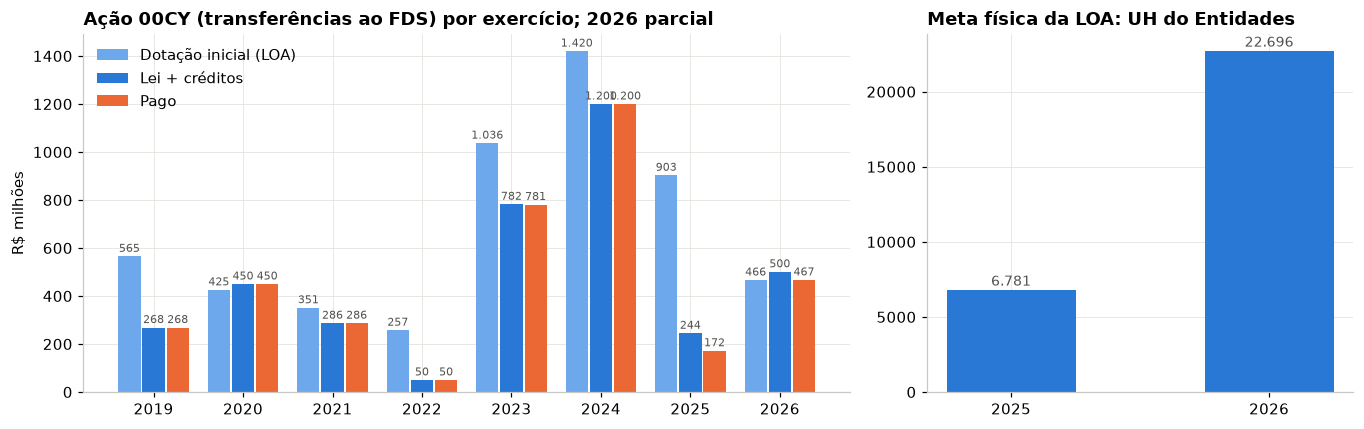

,dotacao_inicial,lei_mais_credito,empenhado,liquidado,pago
ano,,,,,
2022,"R$ 257,21 mi","R$ 50,00 mi","R$ 50,00 mi","R$ 50,00 mi","R$ 50,00 mi"
2023,"R$ 1,04 bi","R$ 781,84 mi","R$ 780,84 mi","R$ 780,84 mi","R$ 780,84 mi"
2024,"R$ 1,42 bi","R$ 1,20 bi","R$ 1,20 bi","R$ 1,20 bi","R$ 1,20 bi"
2025,"R$ 902,59 mi","R$ 244,49 mi","R$ 171,59 mi","R$ 171,59 mi","R$ 171,59 mi"
2026,"R$ 466,07 mi","R$ 500,50 mi","R$ 466,57 mi","R$ 466,57 mi","R$ 466,57 mi"


Pago 2023 a 2026: R$ 2,62 bi; em 2025 o autorizado caiu para 27% da dotação inicial


In [3]:
# Linha do tempo da 00CY: SIOP 2009 a 2026 (pasta de fontes) conferido com a prata em 2025
siop = pd.read_csv(FONTES / "orcamento_siop_serie_00cy_2009_2026.txt", skiprows=2)
siop.columns = ["ano","dotacao_inicial","lei_mais_credito","empenhado","liquidado","pago"]
siop = siop.set_index("ano")
META_UH = {2025: 6781, 2026: 22696}   # meta física da LOA (Volume IV), ver caixa vermelha
print("Conferência 2025, SIOP x prata (SIAFI):", f"dotação {brl(siop.loc[2025,'dotacao_inicial'])} x {brl(fds25.dotacao_inicial)} | pago {brl(siop.loc[2025,'pago'])} x {brl(fds25.despesas_pagas)}")
tl = siop.loc[2019:2026]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4), gridspec_kw={"width_ratios": [1.8, 1]})
x = np.arange(len(tl)); w = 0.27
for i, (col, rot, cor) in enumerate([("dotacao_inicial","Dotação inicial (LOA)",SEQ[2]),("lei_mais_credito","Lei + créditos",C["azul"]),("pago","Pago",C["laranja"])]):
    axes[0].bar(x + (i-1)*w, tl[col]/1e6, w*0.92, label=rot, color=cor)
axes[0].set_xticks(x); axes[0].set_xticklabels(tl.index); axes[0].set_ylabel("R$ milhões"); axes[0].legend(loc="upper left")
axes[0].set_title("Ação 00CY (transferências ao FDS) por exercício; 2026 parcial")
rotular_barras(axes[0], fmt=lambda v: f"{v:,.0f}".replace(",", "."), fontsize=7)
axes[1].bar([str(k) for k in META_UH], list(META_UH.values()), color=C["azul"], width=0.5); axes[1].set_title("Meta física da LOA: UH do Entidades"); rotular_barras(axes[1])
plt.tight_layout(); plt.show()
display(siop.loc[2022:2026].style.format(brl))
print(f"Pago 2023 a 2026: {brl(siop.loc[2023:2026,'pago'].sum())}; em 2025 o autorizado caiu para {100*siop.loc[2025,'lei_mais_credito']/siop.loc[2025,'dotacao_inicial']:.0f}% da dotação inicial")

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: a série da 00CY fora de 2025 e as metas de UH</b><ul style="margin:6px 0 0 0"><li>Só o exercício de 2025 está no banco (<code>prata.prata_conjuntura_siafi_dotacao_execucao</code>, sem coluna de ano). Os demais anos vêm de <code>orcamento_siop_serie_00cy_2009_2026.txt</code> (consulta SPARQL ao SIOP em 01/09/2026) em <code>mapeamento-fluxos/fontes_pesquisa_2026-09-01/</code>; os valores de 2025 batem com a prata, o que confirma o exercício da extração.</li><li>As metas físicas (6.781 UH em 2025, 22.696 em 2026) são do Volume IV das LOAs, lidas no estudo do fluxo (<code>FLUXO_MCMV_ENTIDADES.md</code>), digitadas no código.</li><li><b>Como levar ao banco:</b> uma extração do Tesouro Gerencial por exercício com coluna <code>exercicio</code> na bronze e na prata do SIAFI; e a seed <code>orcamento_00cy_anual.csv</code> (ano, dotacao_inicial, lei_mais_credito, pago, uh_meta_loa, fonte), no molde de <code>seeds.orcamento_fundo_social_mcmv</code>.</li></ul></div>

**Leitura.** O FDS é pequeno perto do FAR: em 2025 a LOA previa R$ 903 mi e a União pagou R$ 172 mi, um quinto; em 2024 tinham sido R$ 1,2 bi. O secretário explicou o mecanismo: o fundo tem saldo acumulado (ele falou em "2 bilhões depositados") e a carteira consome pouco por mês até que uma leva de contratações muda o patamar. É por isso que a execução da 00CY não acompanha a contratação: o que paga a obra é o saldo do FDS na CAIXA, que não está em nenhuma base do Gov Hub. A seção 6 mostra o consumo mensal real do fundo pelo livro-razão.

## 2. Planejamento e seleção: do ciclo à portaria de seleção

O mapa coloca aqui a portaria de abertura do ciclo (meta por UF pelo déficit da FJP), a apresentação de propostas pela EO ao agente financeiro, o enquadramento, os resultados provisório e definitivo e a portaria de seleção do MCID. O banco não tem o funil de propostas do FDS (não existe um consolidado do GFAR para o Entidades como há para o FAR). O que existe: a lista de propostas selecionadas no ciclo 2025/26 (`seeds.portaria_698_2026`, 393 propostas) e a carteira contratada do ciclo 2023/24 (`prata.prata_fds_empreendimento`, 364 APFs, com o `id_proposta` de cada contrato).

In [4]:
emp = cache("fds_empreendimento", "select * from prata.prata_fds_empreendimento")
for c in ["dt_contratacao","dt_inicio_obra","dt_previsao_conclusao","dt_paralisacao","dt_conclusao_obra","dt_entrega","dt_previsao_entrega","dt_ultima_liberacao","dt_aprovacao_pts","dt_substituicao_eo","dt_invasao"]:
    emp[c] = pd.to_datetime(emp[c])
emp.loc[emp.dt_previsao_conclusao < "2000-01-01", "dt_previsao_conclusao"] = pd.NaT   # sentinela 1900-01-01
emp["eo_cnpj"] = emp.eo_cnpj.str.zfill(14)
p698 = cache("seed_portaria_698_2026", 'select "IDENTIFICACAO DA PROPOSTA" id_proposta, "UF" uf, "MUNICÍPIO" municipio, "CNPJ ENTIDADE" cnpj_eo, "NOME DO EMPREENDIMENTO" nome, "UH" uh from seeds.portaria_698_2026')
p698["cnpj_eo"] = p698.cnpj_eo.astype(str).str.zfill(14)

# Ciclos (datas e metas das portarias: ver caixa vermelha)
CICLOS = pd.DataFrame([
    {"ciclo": "2023/24", "abertura": "862/2023 (04/07/2023)", "meta_uh": 16000, "selecao": "355/2024 (09/04/2024)", "uh_selecionadas": np.nan, "prazo_contratacao": "02/09/2025 (prorrogado a 03/10/2025)", "contratos_no_banco": len(emp), "uh_contratadas": emp.quantidade_uh.sum()},
    {"ciclo": "2025/26", "abertura": "927/2025 (22/08/2025)", "meta_uh": 21282, "selecao": "698/2026 (17/06/2026)", "uh_selecionadas": p698.uh.sum(), "prazo_contratacao": "150 dias (até nov/2026)", "contratos_no_banco": 0, "uh_contratadas": 0},
]).set_index("ciclo")
display(CICLOS.style.format({"meta_uh": num, "uh_selecionadas": num, "uh_contratadas": num}, na_rep="–"))
cad_id = cache("fds_cadastro_id_proposta", "select apf, id_proposta from prata.prata_fds_cadastro_pj")
print(f"Propostas da 698/2026 com o mesmo id_proposta de algum contrato da carteira: {cad_id.id_proposta.isin(p698.id_proposta).sum()} (ciclos diferentes, como esperado)")
eo_698 = set(p698.cnpj_eo); eo_cart = set(emp.eo_cnpj)
print(f"Entidades selecionadas na 698/2026: {len(eo_698)}; das quais já têm contrato na carteira 2023/24: {len(eo_698 & eo_cart)} ({num(p698[p698.cnpj_eo.isin(eo_cart)].uh.sum())} UH selecionadas com elas)")

,abertura,meta_uh,selecao,uh_selecionadas,prazo_contratacao,contratos_no_banco,uh_contratadas
ciclo,,,,,,,
2023/24,862/2023 (04/07/2023),16.000,355/2024 (09/04/2024),–,02/09/2025 (prorrogado a 03/10/2025),364,30.731
2025/26,927/2025 (22/08/2025),21.282,698/2026 (17/06/2026),35.820,150 dias (até nov/2026),0,0


Propostas da 698/2026 com o mesmo id_proposta de algum contrato da carteira: 0 (ciclos diferentes, como esperado)
Entidades selecionadas na 698/2026: 200; das quais já têm contrato na carteira 2023/24: 60 (17.146 UH selecionadas com elas)


<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: datas, metas e prazos das portarias dos ciclos</b><ul style="margin:6px 0 0 0"><li>A abertura (862/2023, 927/2025), o resultado (355/2024, 698/2026), as metas (16.000 e 21.282 UH) e o prazo de contratação vêm dos textos na pasta de fontes (<code>rito_portaria862_2023_selecao.txt</code>, <code>selecao_portaria927_2025.txt</code>, <code>panorama_selecao_2023-2024_resultado.txt</code>, <code>rito_portaria698_2026_resultado.txt</code>) e do <code>FLUXO_MCMV_ENTIDADES.md</code>. A 698/2026 está no banco como seed (<code>seeds.portaria_698_2026</code>); a 355/2024 não.</li><li><b>Como levar ao banco:</b> seed <code>fds_portarias_ciclo.csv</code> (ciclo, portaria, tipo, data_publicacao, meta_uh, prazo_contratacao, url) e a lista de propostas da 355/2024 como seed, no mesmo molde da 698/2026, para ligar <code>id_proposta</code> do cadastro PJ à seleção.</li></ul></div>

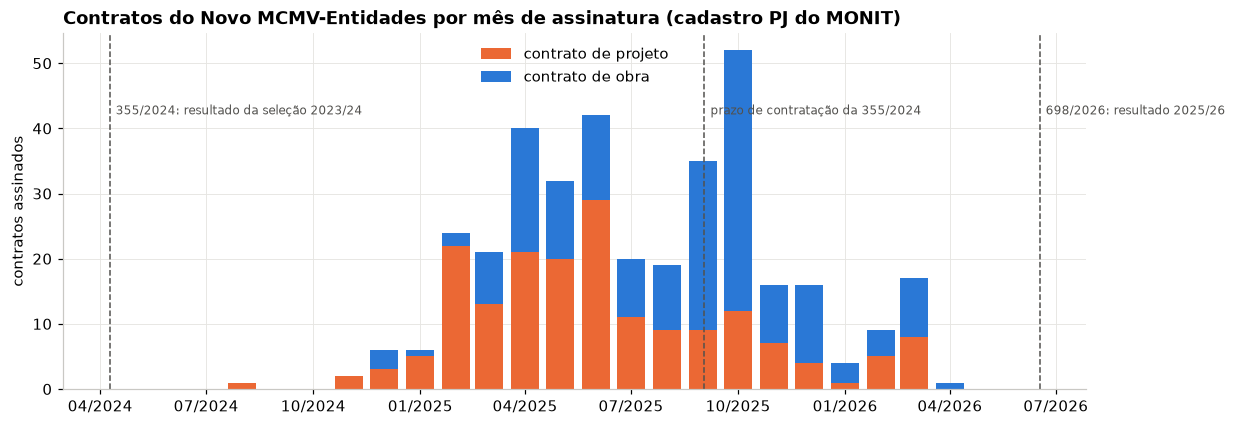

Contratos por trimestre e fase:


apfs            uh        
fase_contrato  OBRA PROJETO  OBRA PROJETO
dt_contratacao                           
2024Q3            0       1     0      50
2024Q4            3       5   800     780
2025Q1           11      40   965    2565
2025Q2           44      70  3250    5333
2025Q3           45      29  3112    2323
2025Q4           61      23  5108    1513
2026Q1           16      14  2274    2078
2026Q2            1       0   148       0

In [5]:
# Contratações mês a mês, por fase do contrato, com as portarias do ciclo no calendário
cm = emp.dropna(subset=["dt_contratacao"]).groupby([emp.dt_contratacao.dt.to_period("M"), "fase_contrato"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4.2))
x = cm.index.to_timestamp()
ax.bar(x, cm.get("PROJETO", 0), width=24, color=FASE_C["PROJETO"], label="contrato de projeto")
ax.bar(x, cm.get("OBRA", 0), width=24, bottom=cm.get("PROJETO", 0), color=FASE_C["OBRA"], label="contrato de obra")
for d, rot in [("2024-04-09", "355/2024: resultado da seleção 2023/24"), ("2025-09-02", "prazo de contratação da 355/2024"), ("2026-06-17", "698/2026: resultado 2025/26")]:
    ax.axvline(pd.Timestamp(d), color="#52514e", lw=1, ls="--"); ax.annotate(rot, (pd.Timestamp(d), ax.get_ylim()[1]*0.80), xytext=(4, 0), textcoords="offset points", fontsize=8, va="top", color="#52514e")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y")); ax.set_ylabel("contratos assinados"); ax.legend(loc="upper center")
ax.set_title("Contratos do Novo MCMV-Entidades por mês de assinatura (cadastro PJ do MONIT)")
plt.show()
print("Contratos por trimestre e fase:"); display(emp.groupby([emp.dt_contratacao.dt.to_period("Q"), "fase_contrato"]).agg(apfs=("apf","size"), uh=("quantidade_uh","sum")).unstack(fill_value=0))

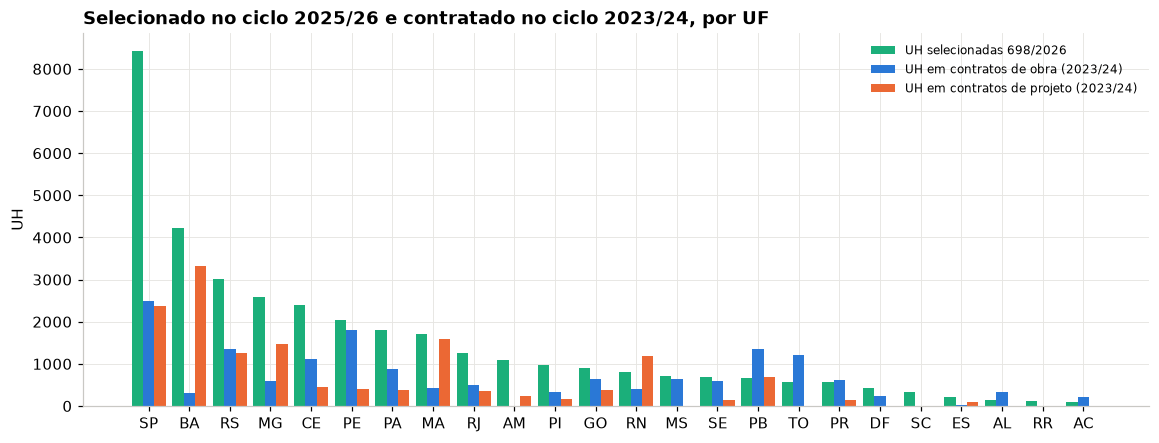

Ciclo 2025/26: 35.820 UH selecionadas em 24 UFs e 217 municípios; ciclo 2023/24 contratado: 16.089 UH em obra e 14.642 UH em projeto


In [6]:
# O que foi selecionado em 2025/26 e o que já está contratado do ciclo anterior, por UF
uf_sel = p698.groupby("uf").uh.sum().rename("UH selecionadas 698/2026")
uf_con = emp[emp.fase_contrato == "OBRA"].groupby("uf").quantidade_uh.sum().rename("UH em contratos de obra (2023/24)")
uf_prj = emp[emp.fase_contrato == "PROJETO"].groupby("uf").quantidade_uh.sum().rename("UH em contratos de projeto (2023/24)")
u = pd.concat([uf_sel, uf_con, uf_prj], axis=1).fillna(0).sort_values("UH selecionadas 698/2026", ascending=False)
fig, ax = plt.subplots(figsize=(12.5, 4.4))
x = np.arange(len(u)); w = 0.28
ax.bar(x - w, u.iloc[:, 0], w, color=C["verde"], label=u.columns[0]); ax.bar(x, u.iloc[:, 1], w, color=FASE_C["OBRA"], label=u.columns[1]); ax.bar(x + w, u.iloc[:, 2], w, color=FASE_C["PROJETO"], label=u.columns[2])
ax.set_xticks(x); ax.set_xticklabels(u.index); ax.set_ylabel("UH"); ax.legend(fontsize=8); ax.set_title("Selecionado no ciclo 2025/26 e contratado no ciclo 2023/24, por UF")
plt.show()
print(f"Ciclo 2025/26: {num(p698.uh.sum())} UH selecionadas em {p698.uf.nunique()} UFs e {p698.municipio.nunique()} municípios; ciclo 2023/24 contratado: {num(uf_con.sum())} UH em obra e {num(uf_prj.sum())} UH em projeto")

**Leitura.** O banco vê a seleção só depois que ela vira contrato. O ciclo 2023/24 produziu os 364 contratos (182 de projeto, 182 de obra), assinados entre agosto de 2024 e abril de 2026, com o pico no segundo semestre de 2025, quando o prazo da 355/2024 vencia. O ciclo 2025/26 selecionou 35,8 mil UH (393 propostas, 200 entidades) em junho de 2026 e ainda não tem nenhum contrato: pelo prazo de 150 dias, a onda de contratação deve aparecer no cadastro até novembro de 2026. O que a SNH pediu, ver a proposta "desde girino" (apresentada, enquadrada, selecionada ou não e por quê), não existe para o FDS: faltam as propostas não selecionadas e o motivo. O pedido ao GEFUS é a extração de propostas do FDS no mesmo leiaute do consolidado do FAR.

## 3. Habilitação das entidades organizadoras

A EO pede habilitação no SISAD e a CAIXA define o **nível**, que limita quantas UH a entidade pode executar ao mesmo tempo. O cadastro PJ traz o código do nível (`co_nivel_hab_eo`, 1 a 6); a habilitação em si (pontuação, validade, abrangência) não está no banco. O secretário quer filtrar por entidade como se filtra por construtora: o panorama por EO (`ouro.ouro_fds_panorama_entidade`) já faz isso.

,entidades,contratos,uh_total,uh_em_obra,uh_em_obra_max,limite,acima_do_limite
nivel,,,,,,,
A,23,126,14.554,8.031,1.720,1.000,2
B,19,49,4.467,1.719,300,750,0
C,16,41,3.209,2.138,338,500,0
D,27,40,3.132,1.869,200,200,0
E,25,38,2.112,910,100,100,0
F,65,70,3.257,1.422,154,50,2


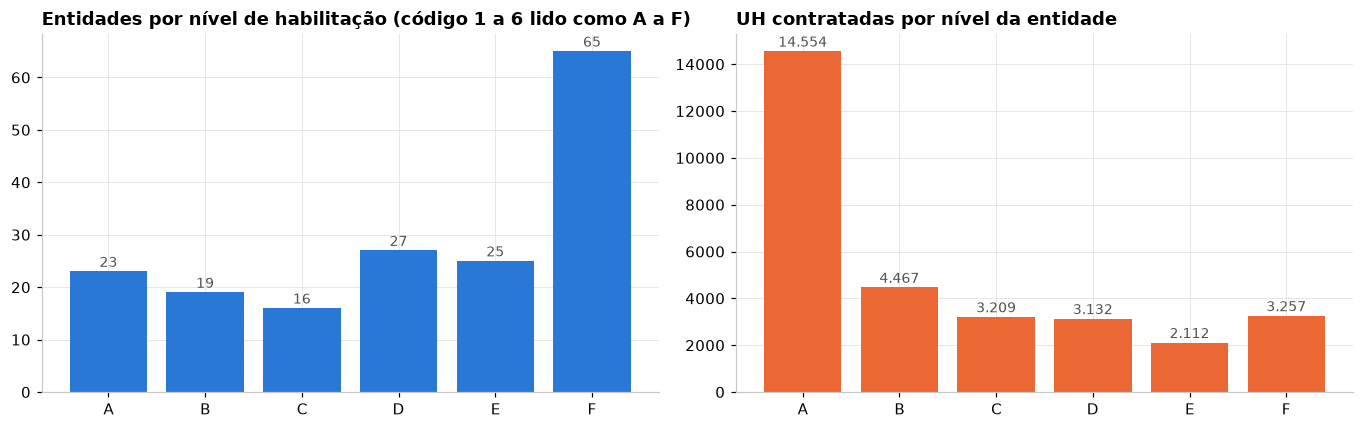

175 entidades; 4 com UH em contratos de obra acima do limite do nível (se a leitura A a F estiver certa)


In [7]:
NIVEL = {1: "A", 2: "B", 3: "C", 4: "D", 5: "E", 6: "F"}            # hipótese de leitura do código, ver caixa vermelha
LIMITE_UH = {"A": 1000, "B": 750, "C": 500, "D": 200, "E": 100, "F": 50}  # Portaria 861/2023, item 7.1 do anexo
emp["nivel"] = emp.co_nivel_hab_eo.map(NIVEL)
eo = emp.groupby("eo_cnpj").agg(nome=("eo_nome","first"), nivel=("nivel","max"), contratos=("apf","size"), obras=("fase_contrato", lambda s: (s == "OBRA").sum()),
                                uh_total=("quantidade_uh","sum"), ufs=("uf","nunique"), municipios=("cod_ibge","nunique"), investimento=("valor_contratado","sum"),
                                exec_fisica=("percentual_execucao_fisica","mean"), paralisadas=("situacao_gefus", lambda s: (s == "PARALISADA").sum()))
eo["uh_em_obra"] = emp[emp.fase_contrato == "OBRA"].groupby("eo_cnpj").quantidade_uh.sum().reindex(eo.index).fillna(0).astype(int)
eo["limite"] = eo.nivel.map(LIMITE_UH); eo["acima_do_limite"] = eo.uh_em_obra > eo.limite
t = eo.groupby("nivel").agg(entidades=("nome","size"), contratos=("contratos","sum"), uh_total=("uh_total","sum"), uh_em_obra=("uh_em_obra","sum"), uh_em_obra_max=("uh_em_obra","max"), limite=("limite","first"), acima_do_limite=("acima_do_limite","sum"))
display(t.style.format({c: num for c in ["contratos","uh_total","uh_em_obra","uh_em_obra_max","limite"]}))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
axes[0].bar(t.index, t.entidades, color=C["azul"]); axes[0].set_title("Entidades por nível de habilitação (código 1 a 6 lido como A a F)"); rotular_barras(axes[0])
axes[1].bar(t.index, t.uh_total, color=C["laranja"]); axes[1].set_title("UH contratadas por nível da entidade"); rotular_barras(axes[1])
plt.tight_layout(); plt.show()
print(f"{len(eo)} entidades; {eo.acima_do_limite.sum()} com UH em contratos de obra acima do limite do nível (se a leitura A a F estiver certa)")

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: a leitura do código do nível (1 a 6 = A a F) e os limites de UH</b><ul style="margin:6px 0 0 0"><li>O banco traz só o código <code>co_nivel_hab_eo</code> (1 a 6), sem dicionário. A leitura 1 = A (1.000 UH) até 6 = F (50 UH) é uma hipótese deste notebook, apoiada na ordem das capacidades observadas (as entidades de código 1 têm as maiores carteiras, as de código 6 as menores). Os limites de UH simultâneas vêm do item 7.1 do anexo da Portaria MCID 861/2023 (<code>rito_portaria861_2023_habilitacao.txt</code> na pasta de fontes); a 1.017/2025 criou os níveis A-Superior (1.500) e A-Nacional (5.000), que não aparecem no código de 1 a 6.</li><li><b>Como levar ao banco:</b> confirmar o dicionário com o GEFUS (leiaute do MONIT_CAD_PJ_FDS) e criar a seed <code>fds_nivel_habilitacao.csv</code> (codigo, nivel, uh_simultaneas_max, portaria); a habilitação em si (SISAD: data, pontuação, abrangência) precisa de uma extração nova, que o secretário disse ser dado interno da SNH.</li></ul></div>

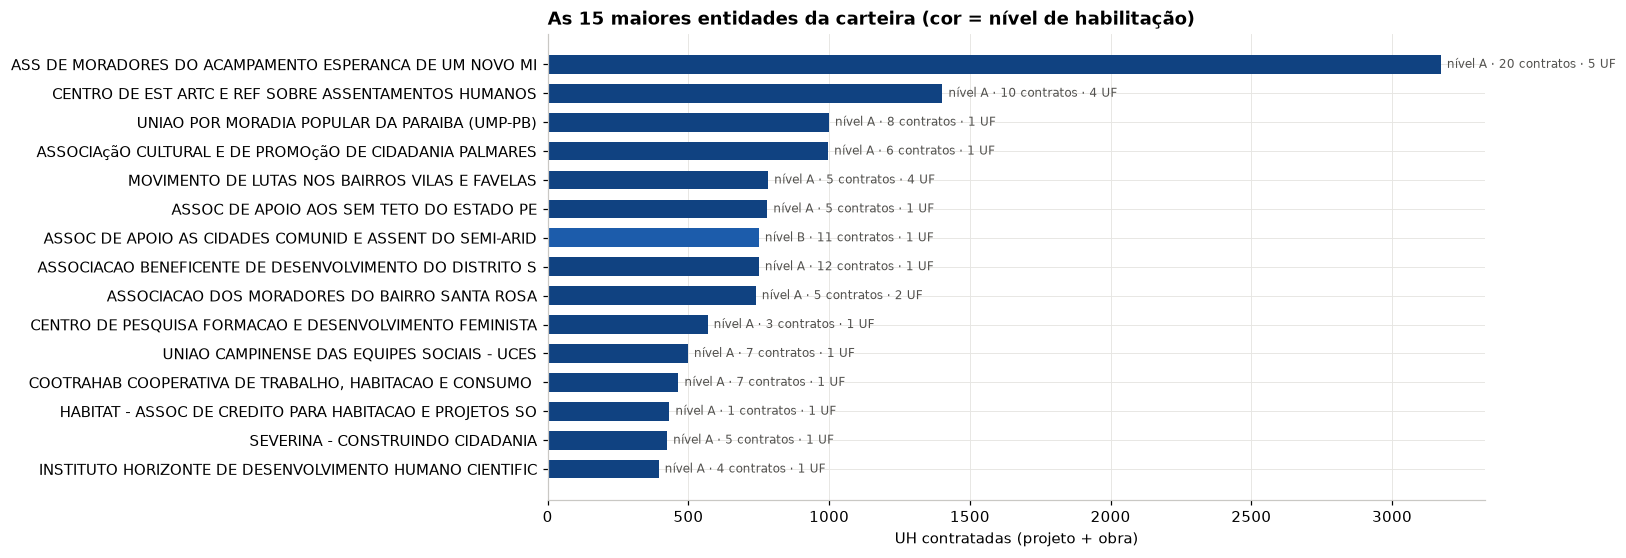

As 10 maiores entidades concentram 36% das UH; as 30 maiores, 58%. Entidades com um só contrato: 108; atuando em mais de uma UF: 4.


In [8]:
# As maiores entidades e a concentração da carteira
top = eo.sort_values("uh_total", ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(top.nome.str[:55], top.uh_total, color=[{"A": SEQ[6], "B": SEQ[5], "C": SEQ[4], "D": SEQ[3], "E": SEQ[2], "F": SEQ[1]}.get(n, C["cinza"]) for n in top.nivel], height=0.65)
for i, (idx, r) in enumerate(top.iterrows()):
    ax.annotate(f"nível {r.nivel} · {r.contratos} contratos · {r.ufs} UF", (r.uh_total, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("UH contratadas (projeto + obra)"); ax.set_title("As 15 maiores entidades da carteira (cor = nível de habilitação)")
plt.show()
s = eo.uh_total.sort_values(ascending=False).cumsum() / eo.uh_total.sum()
print(f"As 10 maiores entidades concentram {100*s.iloc[9]:.0f}% das UH; as 30 maiores, {100*s.iloc[29]:.0f}%. Entidades com um só contrato: {(eo.contratos == 1).sum()}; atuando em mais de uma UF: {(eo.ufs > 1).sum()}.")

In [9]:
# O panorama por entidade da ouro: risco e execução
pan = cache("fds_panorama_entidade", "select * from ouro.ouro_fds_panorama_entidade")
display(pan.groupby("classificacao_risco").agg(entidades=("cnpj_eo","size"), empreendimentos=("total_empreendimentos","sum"), uh=("total_uhs_contratadas","sum"), obras_atrasadas=("qtd_obras_atrasadas","sum"), paralisadas=("qtd_obras_paralisadas","sum"), divergencia_financeira=("qtd_obras_divergencia_financeira","sum")).reindex(["Baixo Risco","Médio Risco","Alto Risco"]))
print("Entidades de alto risco:"); display(pan[pan.classificacao_risco == "Alto Risco"][["nome_eo","total_empreendimentos","total_uhs_contratadas","media_execucao_fisica","media_execucao_financeira","qtd_obras_atrasadas","qtd_obras_paralisadas","score_risco"]])

,entidades,empreendimentos,uh,obras_atrasadas,paralisadas,divergencia_financeira
classificacao_risco,,,,,,
Baixo Risco,114,180,14182,0,0,0
Médio Risco,59,167,15549,62,0,23
Alto Risco,2,17,1000,9,0,3


Entidades de alto risco:


,nome_eo,total_empreendimentos,total_uhs_contratadas,media_execucao_fisica,media_execucao_financeira,qtd_obras_atrasadas,qtd_obras_paralisadas,score_risco
61,ASSOCIACAO BENEFICENTE DE DESENVOLVIMENTO DO DISTRITO STELA,12,750,18.85,33.33,4,0,7
110,INSTITUTO HABITACIONAL MEDIO PIRACICABA,5,250,13.89,13.09,5,0,5


**Leitura.** A carteira é concentrada: 23 entidades de nível 1 (lido como A) têm quase metade das UH, e uma só entidade (acampamento Esperança de Um Novo Milênio) tem 20 contratos e 3,2 mil UH em cinco estados. Na outra ponta, 65 entidades de nível 6 (F) têm um contrato de 50 UH cada. Se a leitura do código estiver certa, há entidades com UH em obra acima do que o nível permitiria simultaneamente; é um indicador que vale conferir com o GEFUS antes de ir ao painel, porque pode ser leitura errada do código ou contratos de fases diferentes. O score de risco da ouro soma atraso físico, paralisação e divergência financeira; só duas entidades estão em alto risco hoje.

## 4. Contratação: a carteira do Novo MCMV-Entidades

Depois da seleção vêm a triagem e hierarquização das famílias pela EO (lista de 130%), o enquadramento dos CPFs pela CAIXA, a assembleia que elege a CRE e a CAO e os contratos. O banco não tem nada das famílias nem das comissões; tem o contrato, com a composição do investimento, a tipologia, o regime e o terreno.

In [10]:
cad = cache("fds_cadastro_pj", """
select apf, vr_financiamento_fds, vr_total_contrapartidas, vr_total_investimento, vr_total_operacao, vr_terreno, vr_trabalho_social, vr_equipamentos_publicos, vr_equipamento_uso_comum,
       vr_infraestrutura, vr_legalizacao, vr_regularizacao, vr_seguros, vr_vigilancia, vr_contrapartida_estado_infra, vr_contrapartida_estado_terreno, vr_contrapartida_estado_complementar,
       vr_contrapartida_municipio_infra, vr_contrapartida_municipio_terreno, vr_contrapartida_municipio_complementar, vr_contrapartida_outras, ic_terreno_doado, ic_uniao_imovel,
       ic_aquecimento_solar, ic_energia_alternativa, area_terreno, co_modalidade, co_regime_obra, qt_uh_construcao, qt_uh_projeto, id_proposta
from prata.prata_fds_cadastro_pj""")
int059 = cache("fds_int059_novo", """
select apf, situacao_gefus, fase_contrato, regime_construcao, tipo_terreno, tipologia as tipologia_int059, qt_uh_financiadas, pct_obra_realizado, vr_liberado as vr_liberado_int059, dt_contratacao as dt_contratacao_int059, dt_inicio_obra as dt_inicio_obra_int059, dt_termino_obra, dt_movimento
from prata.prata_fds_int_059_caixa_pj where selecao_pmcmv_e = 'NOVO PMCMV-E'""")
ficha = cache("fds_ficha", "select apf, semaforo_alerta, status_ritmo_obra, status_entrega, regime_obra, modalidade, regiao_nome from ouro.ouro_fds_ficha_empreendimento")
emp = emp.merge(cad.drop(columns=["co_modalidade","co_regime_obra","qt_uh_construcao","qt_uh_projeto","id_proposta"]), on="apf", how="left").merge(int059.drop(columns=["situacao_gefus","fase_contrato"]), on="apf", how="left").merge(ficha, on="apf", how="left")
tot = {"apfs": len(emp), "uh": emp.quantidade_uh.sum(), "investimento": emp.valor_contratado.sum(), "fds": emp.valor_financiamento_fds.sum(), "contrapartidas": emp.valor_contrapartidas.sum(), "desembolsado": emp.valor_desembolsado.sum()}
print(f"{tot['apfs']} contratos | {num(tot['uh'])} UH | investimento {brl(tot['investimento'])} | financiamento do FDS {brl(tot['fds'])} | contrapartidas {brl(tot['contrapartidas'])} | desembolsado {brl(tot['desembolsado'])} ({100*tot['desembolsado']/tot['fds']:.0f}% do FDS)")
display(emp.groupby(["fase_contrato","modalidade"]).agg(contratos=("apf","size"), uh=("quantidade_uh","sum"), investimento=("valor_contratado","sum"), fds=("valor_financiamento_fds","sum"), valor_por_uh_mediano=("valor_por_uh","median")).style.format({"uh": num, "investimento": brl, "fds": brl, "valor_por_uh_mediano": brl}))

364 contratos | 30.731 UH | investimento R$ 3,46 bi | financiamento do FDS R$ 2,63 bi | contrapartidas R$ 268,34 mi | desembolsado R$ 376,10 mi (14% do FDS)


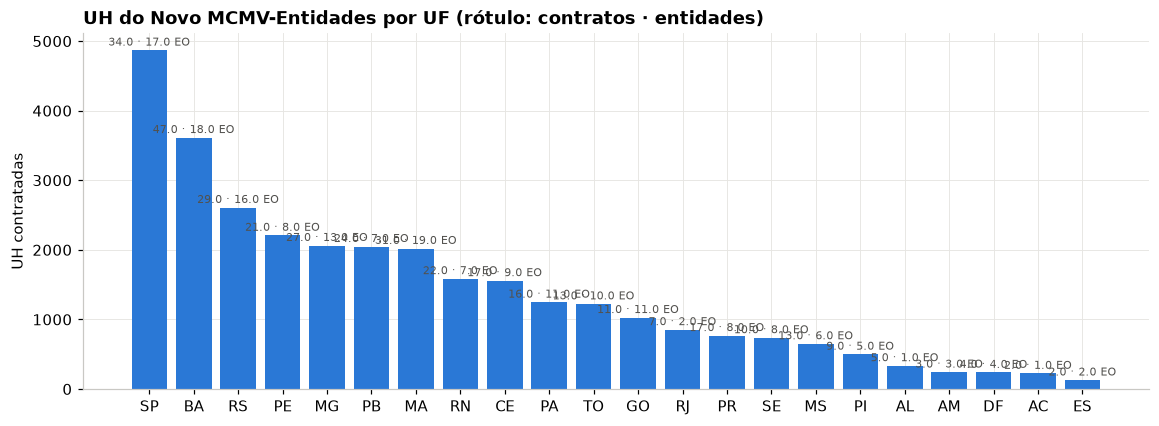

,contratos,obras,uh,entidades,investimento,fds,desembolsado
uf,,,,,,,
SP,34,15,4.869,17,"R$ 696,19 mi","R$ 461,94 mi","R$ 32,14 mi"
BA,47,5,3.613,18,"R$ 104,99 mi","R$ 82,60 mi","R$ 15,66 mi"
RS,29,15,2.608,16,"R$ 290,24 mi","R$ 207,95 mi","R$ 28,08 mi"
PE,21,15,2.208,8,"R$ 342,45 mi","R$ 292,94 mi","R$ 63,55 mi"
MG,27,12,2.062,13,"R$ 176,35 mi","R$ 97,50 mi","R$ 13,40 mi"
PB,24,12,2.047,7,"R$ 273,01 mi","R$ 215,84 mi","R$ 43,53 mi"
MA,31,5,2.019,19,"R$ 88,83 mi","R$ 74,08 mi","R$ 16,81 mi"
RN,22,4,1.585,7,"R$ 106,59 mi","R$ 58,93 mi","R$ 949,58 mil"
CE,17,12,1.556,9,"R$ 183,64 mi","R$ 171,57 mi","R$ 47,15 mi"


In [11]:
# Onde está a carteira: UF (UH, contratos e entidades)
uf = emp.groupby("uf").agg(contratos=("apf","size"), obras=("fase_contrato", lambda s: (s == "OBRA").sum()), uh=("quantidade_uh","sum"), entidades=("eo_cnpj","nunique"), investimento=("valor_contratado","sum"), fds=("valor_financiamento_fds","sum"), desembolsado=("valor_desembolsado","sum")).sort_values("uh", ascending=False)
fig, ax = plt.subplots(figsize=(12.5, 4.2))
ax.bar(uf.index, uf.uh, color=C["azul"])
for i, (idx, r) in enumerate(uf.iterrows()):
    ax.annotate(f"{r.contratos} · {r.entidades} EO", (i, r.uh), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7, color="#52514e")
ax.set_ylabel("UH contratadas"); ax.set_title("UH do Novo MCMV-Entidades por UF (rótulo: contratos · entidades)")
plt.show()
display(uf.style.format({"uh": num, "investimento": brl, "fds": brl, "desembolsado": brl}))

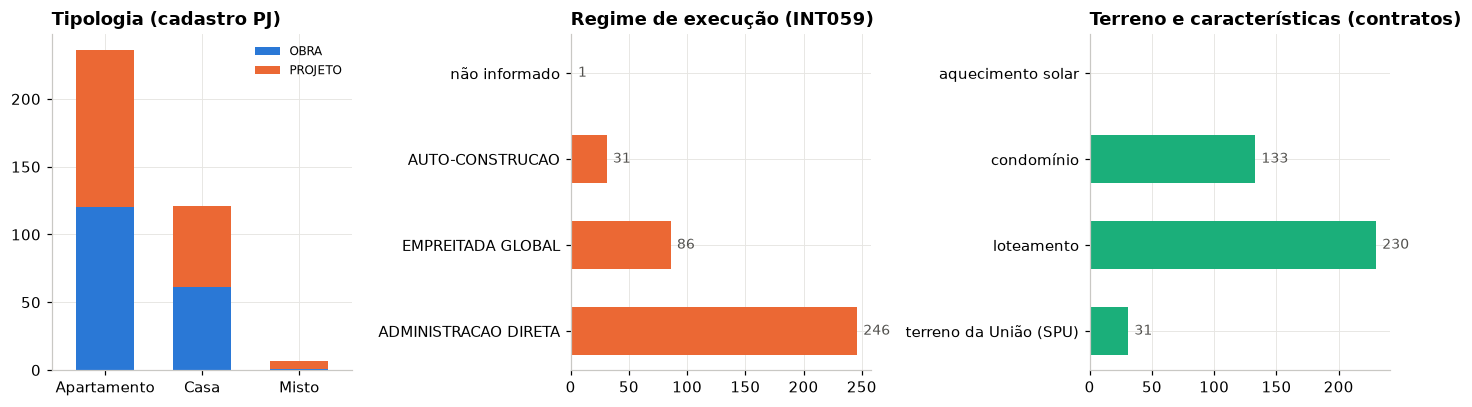

Regime de obra no cadastro PJ (decodificado pela ouro) x regime de execução no INT059:


regime_construcao,ADMINISTRACAO DIRETA,AUTO-CONSTRUCAO,EMPREITADA GLOBAL,não informado,All
regime_obra,,,,,
Autogestão,18,4,65,1,88
Empreitada Global,228,27,21,0,276
All,246,31,86,1,364


In [12]:
# Tipologia, regime e terreno
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
t1 = pd.crosstab(emp.tipologia, emp.fase_contrato)
t1.plot.bar(stacked=True, ax=axes[0], color=[FASE_C[c] for c in t1.columns], width=0.6); axes[0].set_title("Tipologia (cadastro PJ)"); axes[0].set_xlabel(""); axes[0].legend(fontsize=8); plt.setp(axes[0].get_xticklabels(), rotation=0)
t2 = emp.regime_construcao.fillna("não informado").value_counts()
axes[1].barh(t2.index, t2.values, color=C["laranja"], height=0.55); axes[1].set_title("Regime de execução (INT059)"); rotular_barras(axes[1], horizontal=True)
t3 = pd.Series({"terreno da União (SPU)": emp.ic_uniao_imovel.sum(), "loteamento": (emp.tipo_terreno == "LOTEAMENTO").sum(), "condomínio": (emp.tipo_terreno == "CONDOMINIO").sum(), "aquecimento solar": emp.ic_aquecimento_solar.sum()})
axes[2].barh(t3.index, t3.values, color=C["verde"], height=0.55); axes[2].set_title("Terreno e características (contratos)"); rotular_barras(axes[2], horizontal=True)
plt.tight_layout(); plt.show()
print("Regime de obra no cadastro PJ (decodificado pela ouro) x regime de execução no INT059:")
display(pd.crosstab(emp.regime_obra, emp.regime_construcao.fillna("não informado"), margins=True))

**Leitura.** Dois terços dos contratos são de apartamentos e quase tudo é "produção de unidades novas" na fase de obra ou "terreno e projeto" na fase de projeto. O regime é o ponto de atenção: o cadastro PJ (decodificado na ouro como 1 = empreitada global, 2 = autogestão) e o INT059 (administração direta, empreitada global, autoconstrução) discordam na maior parte dos casos, e a tabela cruzada mostra que o código 1 do cadastro casa com "administração direta" no INT059. A decodificação da ouro está provavelmente invertida: no Entidades a regra é autogestão, e o INT059 diz que 246 dos 365 contratos são administração direta. É um dicionário para confirmar com o GEFUS antes de ir ao painel. Os 31 contratos em terreno da União são o começo da meta de 40% em imóveis da SPU do ciclo 2025/26.

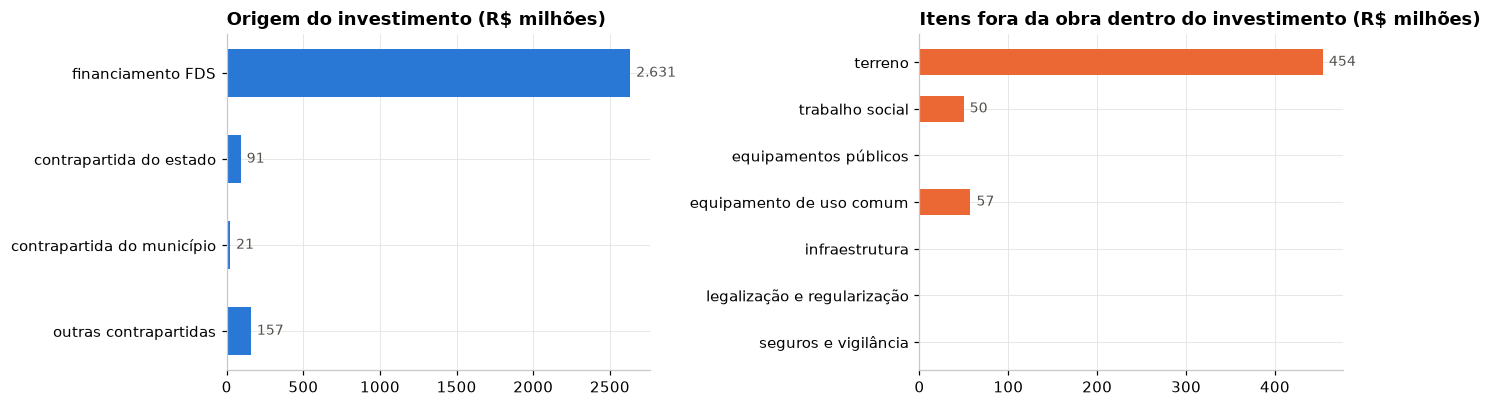

Investimento total R$ 3,46 bi: FDS 76%, contrapartidas 8%; terreno é 13% do investimento


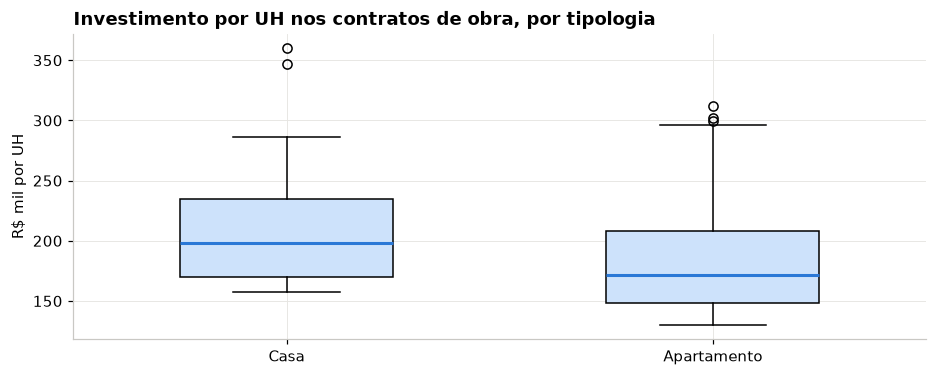

Mediana do investimento por UH (contratos de obra): R$ 178,34 mil | casa: R$ 198,01 mil | apartamento: R$ 171,63 mil


In [13]:
# A composição do investimento: de onde vem e para onde vai o dinheiro contratado
comp = pd.Series({
    "financiamento FDS": emp.vr_financiamento_fds.sum(), "contrapartida do estado": emp[["vr_contrapartida_estado_infra","vr_contrapartida_estado_terreno","vr_contrapartida_estado_complementar"]].sum().sum(),
    "contrapartida do município": emp[["vr_contrapartida_municipio_infra","vr_contrapartida_municipio_terreno","vr_contrapartida_municipio_complementar"]].sum().sum(), "outras contrapartidas": emp.vr_contrapartida_outras.sum()})
dest = pd.Series({"terreno": emp.vr_terreno.sum(), "trabalho social": emp.vr_trabalho_social.sum(), "equipamentos públicos": emp.vr_equipamentos_publicos.sum(), "equipamento de uso comum": emp.vr_equipamento_uso_comum.sum(),
                  "infraestrutura": emp.vr_infraestrutura.sum(), "legalização e regularização": emp.vr_legalizacao.sum() + emp.vr_regularizacao.sum(), "seguros e vigilância": emp.vr_seguros.sum() + emp.vr_vigilancia.sum()})
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
axes[0].barh(comp.index[::-1], comp.values[::-1]/1e6, color=C["azul"], height=0.55); axes[0].set_title("Origem do investimento (R$ milhões)"); rotular_barras(axes[0], fmt=lambda v: f"{v:,.0f}".replace(",", "."), horizontal=True)
axes[1].barh(dest.index[::-1], dest.values[::-1]/1e6, color=C["laranja"], height=0.55); axes[1].set_title("Itens fora da obra dentro do investimento (R$ milhões)"); rotular_barras(axes[1], fmt=lambda v: f"{v:,.0f}".replace(",", "."), horizontal=True)
plt.tight_layout(); plt.show()
print(f"Investimento total {brl(tot['investimento'])}: FDS {100*comp['financiamento FDS']/tot['investimento']:.0f}%, contrapartidas {100*tot['contrapartidas']/tot['investimento']:.0f}%; terreno é {100*dest['terreno']/tot['investimento']:.0f}% do investimento")
fig, ax = plt.subplots(figsize=(10, 3.6))
d = emp[emp.fase_contrato == "OBRA"]
ax.boxplot([d[d.tipologia == t].valor_por_uh/1e3 for t in ["Casa","Apartamento"]], tick_labels=["Casa","Apartamento"], widths=0.5, patch_artist=True, boxprops=dict(facecolor="#cde2fb"), medianprops=dict(color=C["azul"], lw=2))
ax.set_ylabel("R$ mil por UH"); ax.set_title("Investimento por UH nos contratos de obra, por tipologia")
plt.show()
print("Mediana do investimento por UH (contratos de obra):", brl(d.valor_por_uh.median()), "| casa:", brl(d[d.tipologia=="Casa"].valor_por_uh.median()), "| apartamento:", brl(d[d.tipologia=="Apartamento"].valor_por_uh.median()))

## 5. Execução: a obra em autogestão

Os recursos ficam na conta da CRE, a CAO fiscaliza e os pagamentos seguem o avanço. Para enxergar a obra o banco tem três leituras: a **situação GEFUS** do INT059 (normal, não iniciada com cláusula suspensiva, paralisada, concluída), a **situação do MONIT** (`co_situacao_operacao`, mesmos códigos do FAR, decodificados pela seed) e a **medição física** (previsto e realizado da obra mensal). O GEHIS, com "em atenção" e "risco de paralisação", não existe para o FDS.

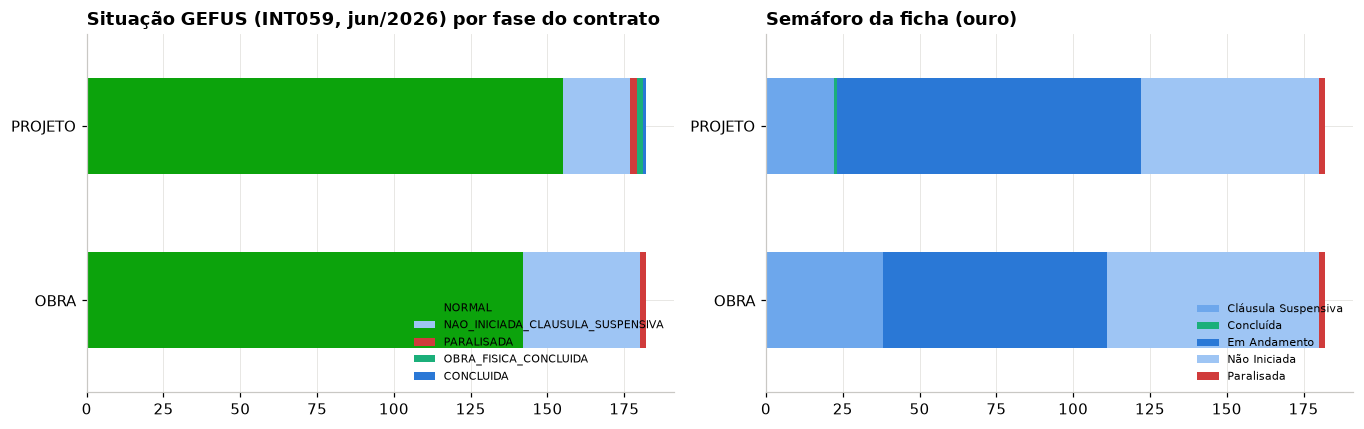

Situação do MONIT (códigos decodificados pela seeds.far_situacao_obra) x situação GEFUS:


situacao_gefus,CONCLUIDA,NAO_INICIADA_CLAUSULA_SUSPENSIVA,NORMAL,OBRA_FISICA_CONCLUIDA,PARALISADA,All
situacao_monit,,,,,,
ATRASADA,0,0,27,0,0,27
CONCLUÍDA,1,0,0,2,0,3
EM ANDAMENTO,0,0,29,0,0,29
NORMAL,0,7,111,0,4,122
NÃO INICIADA,0,53,122,0,0,175
OUTRAS,0,0,7,0,0,7
PARALISADA,0,0,1,0,0,1
All,1,60,297,2,4,364


,contratos,uh,fds,exec_fisica,exec_financeira
situacao_gefus,,,,,
CONCLUIDA,1,50,"R$ 397,70 mil",100.000000,100.000000
NAO_INICIADA_CLAUSULA_SUSPENSIVA,60,5.052,"R$ 456,03 mi",0.200000,2.400000
NORMAL,297,24.433,"R$ 2,07 bi",11.900000,23.400000
OBRA_FISICA_CONCLUIDA,2,194,"R$ 3,10 mi",76.100000,57.500000
PARALISADA,4,1.002,"R$ 97,55 mi",51.000000,68.400000


In [14]:
sit = cache("seed_far_situacao_obra", "select co_situacao_obra, situacao_obra from seeds.far_situacao_obra").astype({"co_situacao_obra": int}).set_index("co_situacao_obra").situacao_obra.to_dict()
emp["situacao_monit"] = emp.co_situacao_operacao.map(sit)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
t = pd.crosstab(emp.fase_contrato, emp.situacao_gefus)[[c for c in GEFUS_C if c in emp.situacao_gefus.unique()]]
t.plot.barh(stacked=True, ax=axes[0], color=[GEFUS_C[c] for c in t.columns], width=0.55); axes[0].set_title("Situação GEFUS (INT059, jun/2026) por fase do contrato"); axes[0].set_ylabel(""); axes[0].legend(fontsize=7, loc="lower right")
t2 = pd.crosstab(emp.fase_contrato, emp.semaforo_alerta)
t2.plot.barh(stacked=True, ax=axes[1], color=[{"Não Iniciada": "#9ec5f4", "Cláusula Suspensiva": SEQ[2], "Em Andamento": C["azul"], "Paralisada": STATUS["critico"], "Concluída": C["verde"]}.get(c, C["cinza"]) for c in t2.columns], width=0.55)
axes[1].set_title("Semáforo da ficha (ouro)"); axes[1].set_ylabel(""); axes[1].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()
print("Situação do MONIT (códigos decodificados pela seeds.far_situacao_obra) x situação GEFUS:")
display(pd.crosstab(emp.situacao_monit, emp.situacao_gefus, margins=True))
t3 = emp.groupby("situacao_gefus").agg(contratos=("apf","size"), uh=("quantidade_uh","sum"), fds=("valor_financiamento_fds","sum"), exec_fisica=("percentual_execucao_fisica","mean"), exec_financeira=("percentual_execucao_financeira","mean")).round(1)
display(t3.style.format({"uh": num, "fds": brl}))

**Leitura.** Dos 364 contratos, 60 estão "não iniciados com cláusula suspensiva" no INT059 (38 de obra, 22 de projeto): o contrato está assinado, mas o dinheiro não sai até a condição ser cumprida. Só quatro estão paralisados, mas são contratos grandes (1.002 UH, duas obras de 256 UH em João Pessoa e dois projetos de 240 e 250 UH). O MONIT diz outra coisa: 175 contratos "não iniciados" (inclui metade dos com cláusula suspensiva) e 27 "atrasados" que o GEFUS chama de normais. São dois vocabulários da própria CAIXA para a mesma obra, o problema que o secretário pediu para depurar; o painel deve mostrar os dois até que o GEFUS e o MONIT se alinhem.

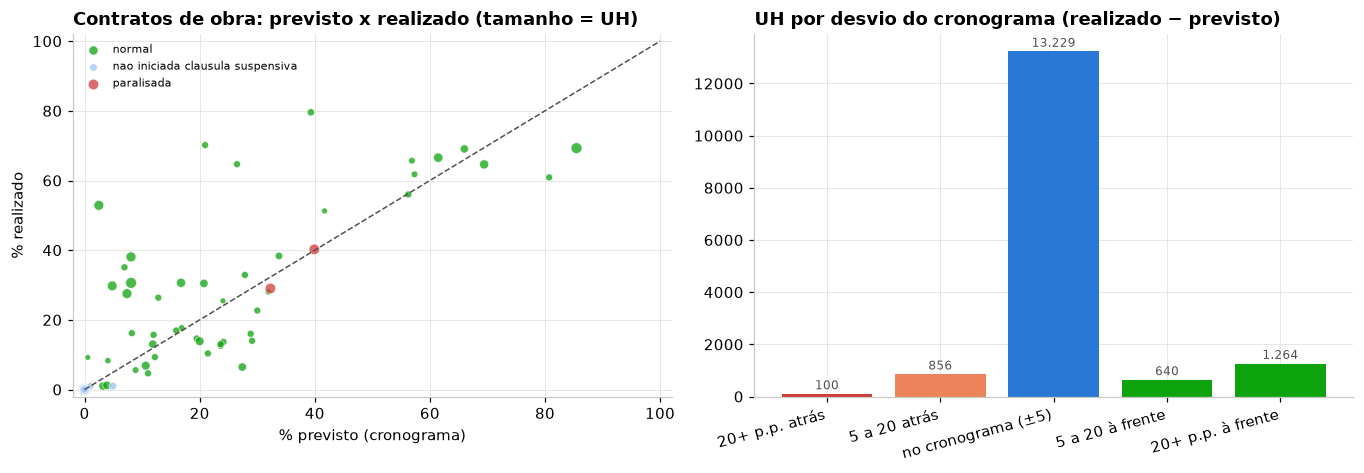

Contratos de obra com medição > 0: 78 de 182; mediana do realizado entre os iniciados: 12.8%; previsto mediano dos mesmos: 8.5%
Obras 5 p.p. ou mais atrás do cronograma: 12 (956 UH); 5 p.p. ou mais à frente: 18


In [15]:
# Previsto x realizado da obra mensal (retrato de julho de 2026)
d = emp[emp.fase_contrato == "OBRA"].copy()
d["desvio"] = d.percentual_execucao_fisica - d.percentual_obra_prevista
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
for s, cor in GEFUS_C.items():
    dd = d[d.situacao_gefus == s]
    if len(dd): ax.scatter(dd.percentual_obra_prevista, dd.percentual_execucao_fisica, s=np.sqrt(dd.quantidade_uh)*3, color=cor, alpha=0.75, label=s.replace("_", " ").lower(), edgecolor="white", lw=0.5)
ax.plot([0, 100], [0, 100], color="#52514e", lw=1, ls="--"); ax.set_xlabel("% previsto (cronograma)"); ax.set_ylabel("% realizado"); ax.set_xlim(-2, 102); ax.set_ylim(-2, 102); ax.legend(fontsize=7, loc="upper left")
ax.set_title("Contratos de obra: previsto x realizado (tamanho = UH)")
ax = axes[1]
d["faixa"] = pd.cut(d.desvio, [-101, -20, -5, 5, 20, 101], labels=["20+ p.p. atrás", "5 a 20 atrás", "no cronograma (±5)", "5 a 20 à frente", "20+ p.p. à frente"])
fx = d.groupby("faixa", observed=False).quantidade_uh.sum()
ax.bar(fx.index.astype(str), fx.values, color=[STATUS["critico"], STATUS["serio"], C["azul"], STATUS["bom"], STATUS["bom"]]); ax.set_title("UH por desvio do cronograma (realizado − previsto)"); rotular_barras(ax, fontsize=8)
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
plt.tight_layout(); plt.show()
print(f"Contratos de obra com medição > 0: {(d.percentual_execucao_fisica > 0).sum()} de {len(d)}; mediana do realizado entre os iniciados: {d[d.percentual_execucao_fisica > 0].percentual_execucao_fisica.median():.1f}%; previsto mediano dos mesmos: {d[d.percentual_execucao_fisica > 0].percentual_obra_prevista.median():.1f}%")
print(f"Obras 5 p.p. ou mais atrás do cronograma: {(d.desvio < -5).sum()} ({num(d[d.desvio < -5].quantidade_uh.sum())} UH); 5 p.p. ou mais à frente: {(d.desvio > 5).sum()}")

### A curva S por mês de contrato

O secretário pediu a curva S por mês contado da contratação, nunca por mês calendário, lida junto com o financeiro. A série física do FDS está no eixo histórico (`prata.prata_hist_fds_empreendimento`): os Dados Prioritários mensais da CAIXA de dezembro de 2024 a março de 2026, a obra mensal do MONIT (abril, maio e julho de 2026) e o INT059 de junho de 2026. Cada APF é deslocado para o mês 0 da sua contratação; a régua é a média aparada (entre o p20 e o p80, como o Mintsu sugeriu), separada por fase do contrato, porque o "físico" do contrato de projeto mede o projeto e não a obra.

4537 observações APF x mês, 363 APFs, de 09/2024 a 07/2026; fontes: {'snh': 3086, 'obra_mensal': 1084, 'sftp': 367}


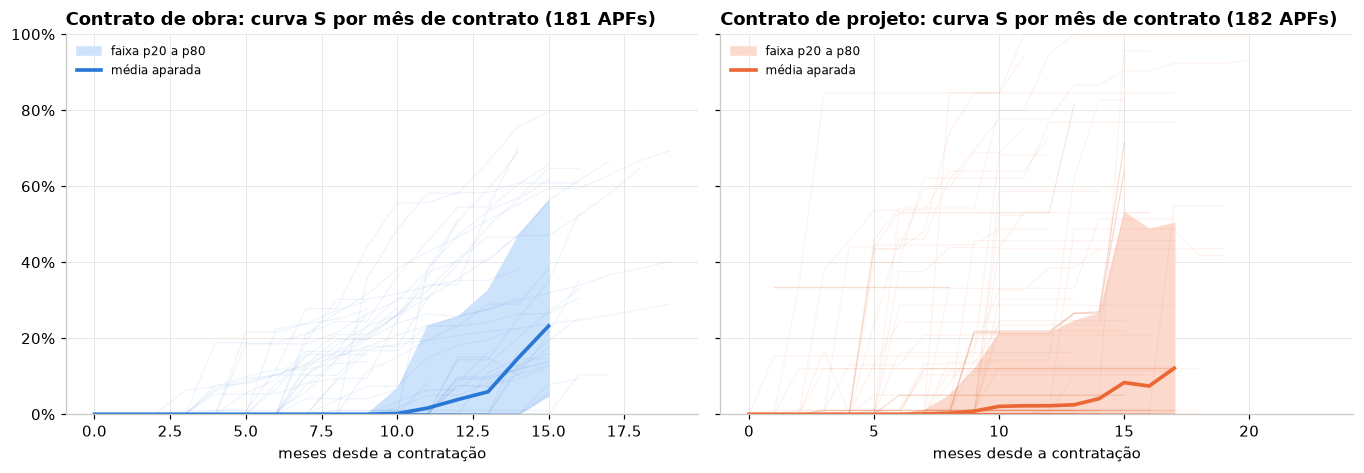

Contratos de obra: média aparada do físico no 3º, 6º, 9º e 12º mês de contrato: {3: 0.0, 6: 0.0, 9: 0.0, 12: 3.9}
Contratos de projeto: {3: 0.0, 6: 0.0, 9: 0.8, 12: 2.2}
Contratos de obra com físico > 0 por mês de contrato (%): {3: 2.0, 6: 12.0, 9: 31.0, 12: 61.0, 15: 94.0}


In [16]:
hist = cache("fds_hist_serie_novo", """
select apf, dt_referencia, fonte_serie, percentual_execucao_fisica, pc_obra_realizada, pc_obra_prevista, valor_desembolsado, status_operacional, quantidade_uh_entregues
from prata.prata_hist_fds_empreendimento where apf in (select apf from prata.prata_fds_empreendimento)""")
hist["mes"] = pd.to_datetime(hist.dt_referencia)
hist["pct"] = hist.percentual_execucao_fisica.fillna(hist.pc_obra_realizada)
sm = hist.dropna(subset=["pct"]).groupby(["apf","mes"]).agg(pct=("pct","max"), pct_prev=("pc_obra_prevista","max"), fontes=("fonte_serie", lambda s: "+".join(sorted(set(s))))).reset_index()
sm = sm.merge(emp[["apf","fase_contrato","dt_contratacao","quantidade_uh","valor_financiamento_fds","situacao_gefus","uf"]], on="apf")
sm["mes_contrato"] = (sm.mes.dt.year - sm.dt_contratacao.dt.year)*12 + (sm.mes.dt.month - sm.dt_contratacao.dt.month)
sm = sm[sm.mes_contrato >= 0]
print(f"{len(sm)} observações APF x mês, {sm.apf.nunique()} APFs, de {sm.mes.min():%m/%Y} a {sm.mes.max():%m/%Y}; fontes: {sm.fontes.value_counts().to_dict()}")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
for ax, fase in zip(axes, ["OBRA", "PROJETO"]):
    d = sm[sm.fase_contrato == fase]
    r = regua(d, "mes_contrato", min_n=15)
    ax.fill_between(r.index, r.p20, r.p80, color="#cde2fb" if fase == "OBRA" else "#fbd9cc", label="faixa p20 a p80")
    ax.plot(r.index, r.media_aparada, color=FASE_C[fase], lw=2.4, label="média aparada")
    for apf, dd in d.groupby("apf"):
        ax.plot(dd.mes_contrato, dd.pct, color=FASE_C[fase], alpha=0.08, lw=0.8)
    ax.set_ylim(0, 100); ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_xlabel("meses desde a contratação"); ax.legend(fontsize=8, loc="upper left")
    ax.set_title(f"Contrato de {fase.lower()}: curva S por mês de contrato ({d.apf.nunique()} APFs)")
plt.tight_layout(); plt.show()
r_obra = regua(sm[sm.fase_contrato == "OBRA"], "mes_contrato"); r_proj = regua(sm[sm.fase_contrato == "PROJETO"], "mes_contrato")
print("Contratos de obra: média aparada do físico no 3º, 6º, 9º e 12º mês de contrato:", {k: round(v, 1) for k, v in r_obra.media_aparada.reindex([3, 6, 9, 12]).items()})
print("Contratos de projeto:", {k: round(v, 1) for k, v in r_proj.media_aparada.reindex([3, 6, 9, 12]).items()})
share0 = sm[sm.fase_contrato == "OBRA"].groupby("mes_contrato").apply(lambda g: 100*(g.pct > 0).mean())
print("Contratos de obra com físico > 0 por mês de contrato (%):", share0.reindex([3, 6, 9, 12, 15]).round(0).to_dict())

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: a régua da curva S (p20 a p80, média aparada) e a data de hoje</b><ul style="margin:6px 0 0 0"><li>A faixa p20 a p80, a média aparada, o mínimo de 15 APFs por mês e a data de hoje (31/08/2026) são parâmetros deste notebook, seguindo a recomendação do professor Mintsu (23/10/2026). A série física em si vem do banco (eixo histórico e obra mensal), com uma emenda: quando dois retratos existem no mesmo mês, fica o maior.</li><li><b>Como levar ao banco:</b> modelo <code>ouro.ouro_fds_serie_mensal_apf</code> no molde da <code>ouro_far_serie_mensal_apf</code> (APF x mês, físico de todas as fontes, financeiro do livro-razão, mês de contrato) e <code>ouro.ouro_fds_curva_s</code> com os parâmetros da régua como vars do dbt.</li></ul></div>

**Leitura.** A curva S do Entidades ainda está no começo: no 12º mês de contrato a média aparada do físico é de 4%, quatro em dez contratos de obra ainda não têm medição positiva um ano depois da assinatura, e só no 15º mês quase todos têm. Não é só atraso: é o desenho da linha, em que o contrato de obra é assinado antes de a cláusula suspensiva cair e de a CRE receber a primeira parcela, e a CAIXA informa zero até a primeira medição. Os contratos de projeto andam mais rápido (o projeto chega a 100% em um ano para parte deles), e é aí que a fase seguinte do fluxo, o contrato de obra, deveria nascer. A faixa p20 a p80 é larga porque a carteira mistura obras que já andam com obras à espera; a régua vai ficar útil quando a carteira tiver mais contratos além do 12º mês. O financeiro, na seção 6, está adiante do físico por desenho (parcelas antecipadas por porte).

,contratos,uh,fds
posicao,,,
abaixo da faixa (atrasado),7,505,"R$ 70,10 mi"
acima da faixa (adiantado),16,1.231,"R$ 184,53 mi"
dentro da faixa,144,12.156,"R$ 1,85 bi"


situacao_gefus,NAO_INICIADA_CLAUSULA_SUSPENSIVA,NORMAL
posicao,,
abaixo da faixa (atrasado),0,7
acima da faixa (adiantado),0,16
dentro da faixa,38,106


Os quatro contratos paralisados segundo o INT059 (o MONIT não traz data de paralisação para nenhum deles):


,apf,empreendimento_nome,municipio,uf,fase_contrato,eo_nome,quantidade_uh,dt_contratacao,dt_previsao_conclusao,percentual_obra_prevista,percentual_execucao_fisica,percentual_execucao_financeira,situacao_monit,dt_paralisacao
55,63531550,RESIDENCIAL JARDIM DO SUL,JOÃO PESSOA,PB,OBRA,UNIAO POR MORADIA POPULAR DA PARAIBA (UMP-PB),256,2024-12-19,2026-11-19,39.92,40.24,44.86,NORMAL,NaT
56,63531664,RESIDENCIAL MORADA DO SUL,JOÃO PESSOA,PB,OBRA,UNIAO POR MORADIA POPULAR DA PARAIBA (UMP-PB),256,2024-12-19,2026-11-19,32.29,29.01,35.80,NORMAL,NaT
105,63543385,RESIDENCIAL MAUA SINOS,SÃO LEOPOLDO,RS,PROJETO,"COOTRAHAB COOPERATIVA DE TRABALHO, HABITACAO E CONSUMO CONST",250,2024-12-24,2026-09-04,42.56,41.72,95.22,NORMAL,NaT
110,63545556,RESIDENCIAL TARSILA DO AMARAL,SÃO CARLOS,SP,PROJETO,MOVIMENTO HABITACIONAL E ACAO SOCIAL - MOHAS,240,2024-11-22,2026-08-12,93.04,93.21,97.72,NORMAL,NaT


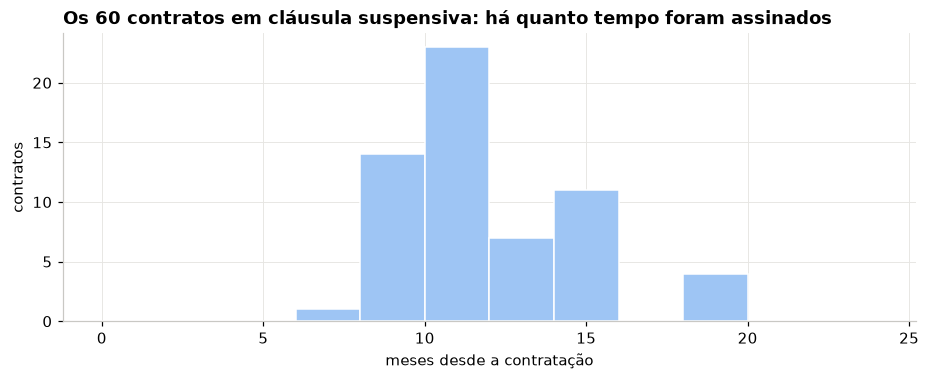

Cláusula suspensiva há mais de 12 meses: 22 contratos (2.141 UH)


In [17]:
# Quem está fora da faixa hoje (contratos de obra, último mês observado)
d = sm[sm.fase_contrato == "OBRA"]
ult = d.sort_values("mes").groupby("apf").tail(1).merge(r_obra[["p20","p80","media_aparada"]], left_on="mes_contrato", right_index=True, how="inner")
ult["posicao"] = np.select([ult.pct < ult.p20, ult.pct > ult.p80], ["abaixo da faixa (atrasado)", "acima da faixa (adiantado)"], "dentro da faixa")
res = ult.groupby("posicao").agg(contratos=("apf","size"), uh=("quantidade_uh","sum"), fds=("valor_financiamento_fds","sum"))
display(res.style.format({"uh": num, "fds": brl}))
display(pd.crosstab(ult.posicao, ult.situacao_gefus))
paral = emp[emp.situacao_gefus == "PARALISADA"][["apf","empreendimento_nome","municipio","uf","fase_contrato","eo_nome","quantidade_uh","dt_contratacao","dt_previsao_conclusao","percentual_obra_prevista","percentual_execucao_fisica","percentual_execucao_financeira","situacao_monit","dt_paralisacao"]]
print("Os quatro contratos paralisados segundo o INT059 (o MONIT não traz data de paralisação para nenhum deles):"); display(paral)
susp = emp[emp.situacao_gefus == "NAO_INICIADA_CLAUSULA_SUSPENSIVA"].copy(); susp["meses_desde_contrato"] = (HOJE - susp.dt_contratacao).dt.days/30.44
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(susp.meses_desde_contrato, bins=range(0, 26, 2), color="#9ec5f4", edgecolor="white"); ax.set_xlabel("meses desde a contratação"); ax.set_ylabel("contratos")
ax.set_title(f"Os {len(susp)} contratos em cláusula suspensiva: há quanto tempo foram assinados"); plt.show()
print(f"Cláusula suspensiva há mais de 12 meses: {(susp.meses_desde_contrato > 12).sum()} contratos ({num(susp[susp.meses_desde_contrato > 12].quantidade_uh.sum())} UH)")

## 6. Desembolso: o dinheiro que saiu do FDS

No Entidades o desembolso não é por medição ao credor: a CAIXA deposita na conta da CRE parcelas antecipadas (16%/8% para até 100 UH, 12%/6% de 101 a 200, 8%/4% acima de 200, com parcela-espelho bloqueada até a prestação de contas) e a CRE paga a obra. O livro-razão do MONIT (`prata.prata_fds_financeiro_mensal`) registra cada liberação com a sua composição, do legado de 2011 até julho de 2026.

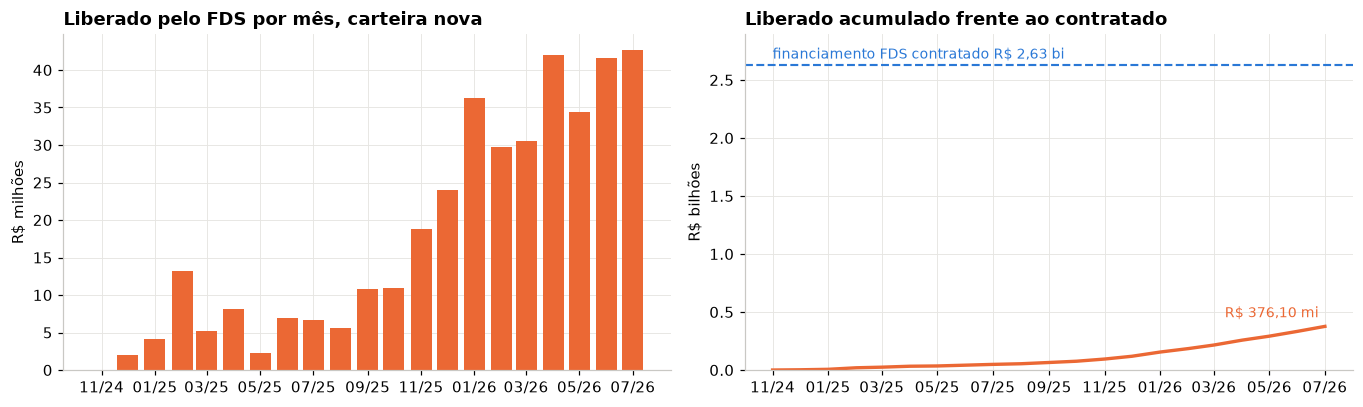

Carteira nova: R$ 376,10 mi em 827 liberações para 197 APFs (14% do FDS contratado); primeira liberação em 11/2024
Ritmo dos últimos 6 meses: R$ 36,84 mi por mês; a esse ritmo, o saldo a liberar (R$ 2,26 bi) leva 5.1 anos


In [18]:
fin = cache("fds_financeiro", """
select apf, dt_liberacao, dt_movimento, co_tipo_movimento, ic_credito, vr_liberado, vr_movimento, vr_pago_obra, vr_pago_terreno, vr_pago_trabalho_social, vr_pago_projeto, vr_pago_aporte, vr_pago_incc, vr_pago_legalizacao, vr_pago_seguranca
from prata.prata_fds_financeiro_mensal""")
fin["dt_liberacao"] = pd.to_datetime(fin.dt_liberacao)
fin["apf_raiz"] = fin.apf.str[-6:]; emp["apf_raiz"] = emp.apf.str[:6]
assert emp.apf_raiz.is_unique, "raiz de 6 dígitos ambígua na carteira"
fin = fin[fin.ic_credito == "0"].copy(); fin["liberado"] = fin.vr_liberado.abs()
for c in ["vr_pago_obra","vr_pago_terreno","vr_pago_trabalho_social","vr_pago_projeto","vr_pago_aporte","vr_pago_incc","vr_pago_legalizacao","vr_pago_seguranca"]: fin[c] = fin[c].abs()
fin["novo"] = fin.apf_raiz.isin(emp.apf_raiz)
fn = fin[fin.novo]
fm = fn.set_index("dt_liberacao").resample("MS").agg(liberacoes=("apf","size"), liberado=("liberado","sum"))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
axes[0].bar(fm.index, fm.liberado/1e6, width=24, color=C["laranja"]); axes[0].set_title("Liberado pelo FDS por mês, carteira nova"); axes[0].set_ylabel("R$ milhões"); axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
axes[1].plot(fm.index, fm.liberado.cumsum()/1e9, color=C["laranja"], lw=2.2, label="liberado acumulado")
axes[1].axhline(tot["fds"]/1e9, color=C["azul"], lw=1.4, ls="--"); axes[1].annotate(f"financiamento FDS contratado {brl(tot['fds'])}", (fm.index[0], tot["fds"]/1e9), xytext=(0, 4), textcoords="offset points", fontsize=9, color=C["azul"])
axes[1].set_title("Liberado acumulado frente ao contratado"); axes[1].set_ylabel("R$ bilhões"); axes[1].set_ylim(0, tot["fds"]/1e9*1.1); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%y"))
axes[1].annotate(brl(fm.liberado.sum()), (fm.index[-1], fm.liberado.sum()/1e9), xytext=(-4, 6), textcoords="offset points", ha="right", fontsize=9, color=C["laranja"])
plt.tight_layout(); plt.show()
ritmo = fm.liberado.tail(6).mean()
print(f"Carteira nova: {brl(fn.liberado.sum())} em {num(len(fn))} liberações para {fn.apf_raiz.nunique()} APFs ({100*fn.liberado.sum()/tot['fds']:.0f}% do FDS contratado); primeira liberação em {fn.dt_liberacao.min():%m/%Y}")
print(f"Ritmo dos últimos 6 meses: {brl(ritmo)} por mês; a esse ritmo, o saldo a liberar ({brl(tot['fds'] - fn.liberado.sum())}) leva {(tot['fds'] - fn.liberado.sum())/ritmo/12:.1f} anos")

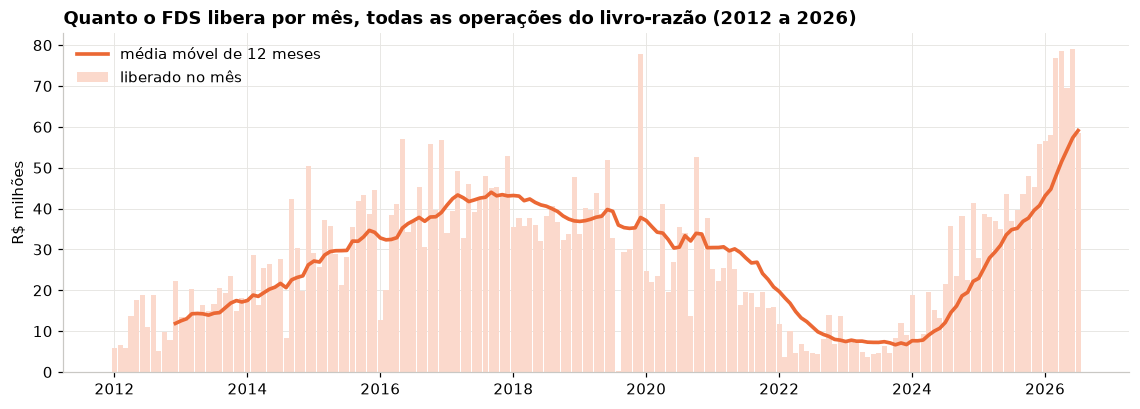

Média mensal liberada por ano (R$ milhões): {2012: 12.0, 2013: 17.0, 2014: 26.0, 2015: 34.0, 2016: 39.0, 2017: 43.0, 2018: 37.0, 2019: 38.0, 2020: 30.0, 2021: 21.0, 2022: 8.0, 2023: 7.0, 2024: 22.0, 2025: 41.0, 2026: 68.0}


In [19]:
# Os patamares do fundo: liberações mensais de toda a carteira do FDS desde 2012 (legado e novo)
fa = fin.set_index("dt_liberacao").resample("MS").liberado.sum().loc["2012":]
fa12 = fa.rolling(12).mean()
fig, ax = plt.subplots(figsize=(12.5, 4))
ax.bar(fa.index, fa/1e6, width=28, color="#fbd9cc", label="liberado no mês")
ax.plot(fa12.index, fa12/1e6, color=C["laranja"], lw=2.4, label="média móvel de 12 meses")
ax.set_ylabel("R$ milhões"); ax.legend(loc="upper left"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Quanto o FDS libera por mês, todas as operações do livro-razão (2012 a 2026)")
plt.show()
pat = fa.groupby(fa.index.year).mean()/1e6
print("Média mensal liberada por ano (R$ milhões):", {int(k): round(v, 0) for k, v in pat.items()})

**Leitura.** O livro-razão conta a história que o secretário descreveu de memória: entre 2015 e 2019 o FDS liberava R$ 35 a 45 milhões por mês para o PMCMV-E; de 2021 a 2023 o consumo caiu a menos de R$ 10 milhões (carteira legada em fim de vida, sem contratação nova); desde 2025 o patamar subiu com os 364 contratos novos e em 2026 passa de R$ 60 milhões por mês, entre legado e novo. A carteira nova sozinha consumiu R$ 376 milhões, 14% do financiamento contratado, e no ritmo dos últimos seis meses (R$ 37 milhões) levaria cinco anos para consumir o resto: ou o ritmo sobe quando as obras saírem da cláusula suspensiva, ou a execução vai muito além do prazo de 24 meses da obra. É esse número, "quanto custa executar a carteira por mês", que ele pediu para a V1.

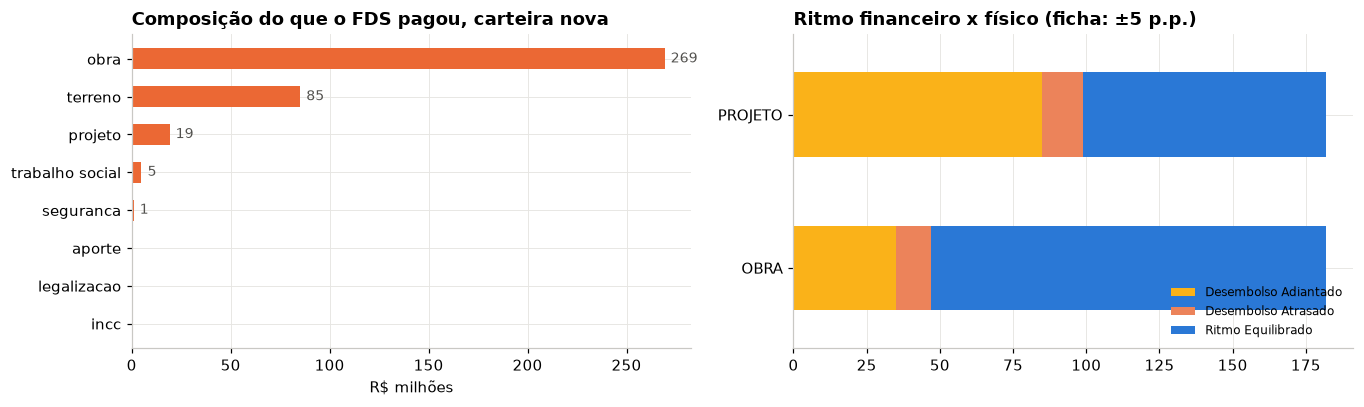

Terreno e projeto somam 27% do liberado; obra, 71%


In [20]:
# Para onde vai o dinheiro e o ritmo financeiro em relação ao físico
comp = fn[["vr_pago_obra","vr_pago_terreno","vr_pago_projeto","vr_pago_trabalho_social","vr_pago_incc","vr_pago_legalizacao","vr_pago_aporte","vr_pago_seguranca"]].sum().sort_values()
comp.index = [i.replace("vr_pago_", "").replace("_", " ") for i in comp.index]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
axes[0].barh(comp.index, comp.values/1e6, color=C["laranja"], height=0.55); axes[0].set_xlabel("R$ milhões"); axes[0].set_title("Composição do que o FDS pagou, carteira nova")
rotular_barras(axes[0], fmt=lambda v: f"{v:,.0f}".replace(",", "."), horizontal=True)
t = pd.crosstab(emp.fase_contrato, emp.status_ritmo_obra)
t.plot.barh(stacked=True, ax=axes[1], color=[{"Desembolso Adiantado": STATUS["atencao"], "Ritmo Equilibrado": C["azul"], "Desembolso Atrasado": STATUS["serio"]}.get(c, C["cinza"]) for c in t.columns], width=0.55)
axes[1].set_title("Ritmo financeiro x físico (ficha: ±5 p.p.)"); axes[1].set_ylabel(""); axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()
print(f"Terreno e projeto somam {100*(comp['terreno'] + comp['projeto'])/comp.sum():.0f}% do liberado; obra, {100*comp['obra']/comp.sum():.0f}%")

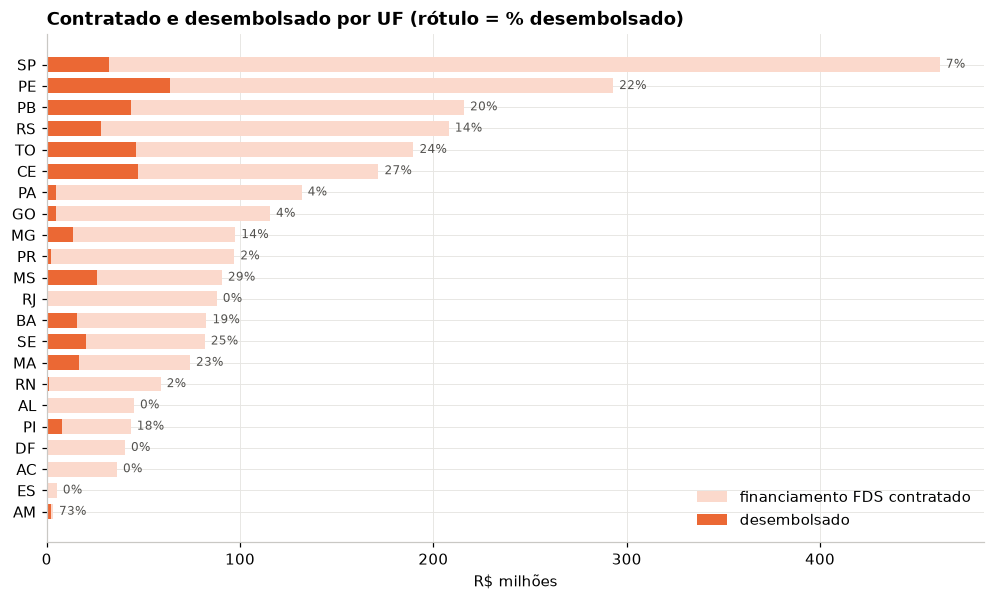

In [21]:
# Desembolso frente ao contratado por UF
u = uf.sort_values("fds")
u["pct_desemb"] = 100*u.desembolsado/u.fds
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(u.index, u.fds/1e6, color="#fbd9cc", height=0.7, label="financiamento FDS contratado")
ax.barh(u.index, u.desembolsado/1e6, color=C["laranja"], height=0.7, label="desembolsado")
for i, (idx, row) in enumerate(u.iterrows()):
    ax.annotate(f"{row.pct_desemb:.0f}%", (row.fds/1e6, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("R$ milhões"); ax.set_title("Contratado e desembolsado por UF (rótulo = % desembolsado)"); ax.legend(loc="lower right")
plt.show()

**Leitura.** O desembolso está adiantado em relação ao físico em um terço dos contratos, e isso é desenho, não problema: as parcelas antecipadas por porte e o terreno e o projeto pagos no começo (um quarto do liberado) colocam o financeiro na frente da medição. Para o Entidades, o "ritmo equilibrado" da ficha precisa de uma régua própria, que desconte a antecipação; usar a mesma régua do FAR (±5 p.p.) marca de amarelo o que é normal aqui.

## 7. Entrega: o que chegou às famílias

O fim do fluxo é a conclusão e legalização da obra, os contratos individuais e a entrega das chaves. No FDS a entrega efetiva é a **alienação** (`qt_uh_alienadas` da obra mensal: a família assinou o contrato com o fundo), não a conclusão. A carteira nova ainda não tem obra concluída; o legado PMCMV-E mostra o que acontece depois.

In [22]:
print("Carteira nova: contratos com UH alienadas, conclusão ou primeiro contrato de família")
obra = cache("fds_obra_mensal", """
select apf, co_situacao_operacao, dt_alteracao_situacao, pct_obra_prevista, pct_obra_realizada, qt_uh_alienadas, qt_uh_a_alienar, qt_uh_concluidas, qt_uh_sem_habitese, dt_primeira_assinatura_pf, dt_ultima_assinatura_pf,
       dt_previsao_entrega, dt_conclusao_obra, dt_legalizacao, dt_entrega, dt_paralisacao, co_classificacao_paralisado, detalhe_paralisacao, dt_movimento
from prata.prata_fds_obra_mensal""")
for c in ["dt_alteracao_situacao","dt_primeira_assinatura_pf","dt_ultima_assinatura_pf","dt_previsao_entrega","dt_conclusao_obra","dt_legalizacao","dt_entrega","dt_paralisacao","dt_movimento"]: obra[c] = pd.to_datetime(obra[c])
e = emp.merge(obra[["apf","dt_primeira_assinatura_pf","qt_uh_a_alienar"]], on="apf", how="left")
display(e[(e.qt_uh_alienadas > 0) | e.situacao_gefus.isin(["CONCLUIDA","OBRA_FISICA_CONCLUIDA"])][["apf","empreendimento_nome","municipio","uf","fase_contrato","situacao_gefus","quantidade_uh","qt_uh_alienadas","dt_primeira_assinatura_pf","percentual_execucao_fisica","dt_contratacao","dt_previsao_conclusao"]])
print("Campos de entrega preenchidos na obra mensal (364 contratos):", {c: int(obra[c].notna().sum()) for c in ["dt_conclusao_obra","dt_legalizacao","dt_entrega","dt_primeira_assinatura_pf","dt_paralisacao"]}, "| UH alienadas:", int(obra.qt_uh_alienadas.sum()))

Carteira nova: contratos com UH alienadas, conclusão ou primeiro contrato de família


,apf,empreendimento_nome,municipio,uf,fase_contrato,situacao_gefus,quantidade_uh,qt_uh_alienadas,dt_primeira_assinatura_pf,percentual_execucao_fisica,dt_contratacao,dt_previsao_conclusao
20,63521095,NOVO ORIZONA,ORIZONA,GO,PROJETO,OBRA_FISICA_CONCLUIDA,50,0,NaT,52.30,2025-08-22,2026-09-22
57,63531778,RESIDENCIAL ANTONIO JUNIOR,JOÃO PESSOA,PB,PROJETO,CONCLUIDA,50,0,NaT,100.00,2024-08-30,2025-09-30
99,63542256,PROJETO CASA NOVA EM LOTES PULVERIZADOS,PORTÃO,RS,OBRA,NORMAL,13,13,2025-11-24,0.00,2025-11-24,2026-11-24
102,63543053,PROJETO UNIAO EM LOTES PULVERIZADOS,SANTO AUGUSTO,RS,OBRA,NORMAL,26,26,2025-07-21,51.27,2025-07-21,2027-03-22
108,63544965,RESIDENCIAL SONHO REAL,RIBEIRÃO PRETO,SP,PROJETO,OBRA_FISICA_CONCLUIDA,144,0,NaT,99.99,2024-11-04,2026-08-04
219,63798729,LOTEAMENTO CASA NOVA LAGAMAR II,LAGAMAR,MG,OBRA,NORMAL,10,10,2025-12-09,0.00,2025-12-09,2027-07-09
281,63798615,LOTEAMENTO NOVA ESPERANCA LAGAMAR I,LAGAMAR,MG,OBRA,NORMAL,15,15,2025-10-30,0.00,2025-10-30,2027-07-30


Campos de entrega preenchidos na obra mensal (364 contratos): {'dt_conclusao_obra': 0, 'dt_legalizacao': 0, 'dt_entrega': 0, 'dt_primeira_assinatura_pf': 4, 'dt_paralisacao': 0} | UH alienadas: 64


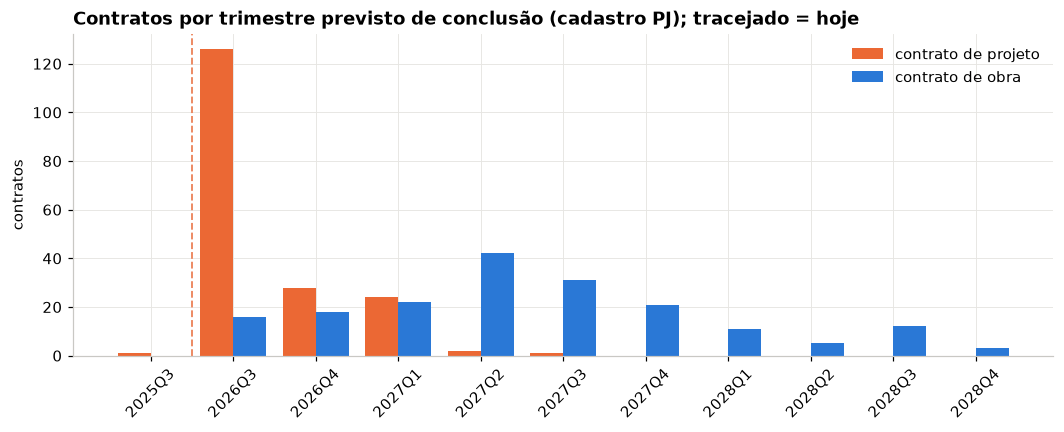

Promessa de conclusão já vencida sem 100%: 115 contratos (8.389 UH): {'PROJETO': 109, 'OBRA': 6}


contratos    uh  exec_media  atraso_medio_meses
fase_contrato situacao_gefus                                                                   
OBRA          NORMAL                                    6   370        44.0                 0.5
PROJETO       NAO_INICIADA_CLAUSULA_SUSPENSIVA         16  1703         0.8                 0.6
              NORMAL                                   92  6076        15.8                 0.7
              PARALISADA                                1   240        93.2                 0.6

As 15 promessas mais vencidas (lista completa em output/fds_contratos_promessa_vencida.csv):


,apf,empreendimento_nome,municipio,uf,fase_contrato,eo_nome,quantidade_uh,dt_contratacao,dt_previsao_conclusao,atraso_meses,percentual_obra_prevista,percentual_execucao_fisica,percentual_execucao_financeira,situacao_gefus,situacao_monit
2,63512661,RESIDENCIAL HABITAR RAMOS II,ALAGOINHAS,BA,PROJETO,ASSOCIAçãO CULTURAL E DE PROMOçãO DE CIDADANIA PALMARES EM M,124,04/06/2025,04/08/2026,0.900000,100.0%,81.5%,89.9%,NORMAL,ATRASADA
40,63526229,OCUPACAO ZEZEU RIBEIRO E NORMA LUCIA,BELO HORIZONTE,MG,PROJETO,COOP DE TRABALHO E SERVIÇO DOS TRABALHADORES AUT SAMAMBAIA,88,12/02/2025,05/08/2026,0.900000,100.0%,45.7%,41.7%,NORMAL,ATRASADA
340,63537927,NECI LIBERATO II,SÃO JULIÃO,PI,PROJETO,"ASSOCIACAO DOS TRABALHADORES DE PORCOS, MACACOS E REGIAO",50,03/10/2025,05/08/2026,0.900000,0.0%,0.0%,67.4%,NORMAL,NORMAL
135,63798947,IRMA MARIA LUIZA,SÃO PAULO,SP,PROJETO,ASSOCIACAO DOS MOVIMENTOS DE MORADIA DA REGIADO SUDESTE,35,05/02/2025,04/08/2026,0.900000,63.6%,76.8%,11.2%,NORMAL,EM ANDAMENTO
130,63797587,TUTOIA,TUTÓIA,MA,PROJETO,INSTITUTO AVA DE DESENVOLVIMENTO SOCIAL,100,21/03/2025,05/08/2026,0.900000,98.0%,10.4%,62.1%,NORMAL,ATRASADA
119,63794623,LOTEAMENTO STEIGLEDER,SÃO LEOPOLDO,RS,PROJETO,"NOVA GERACAO COOPERATIVA DE TRABALHO, HABITACAO E PROJETOS",96,24/12/2024,05/08/2026,0.900000,45.8%,43.5%,12.4%,NORMAL,NORMAL
117,63794391,EMPREENDIMENTO MUTIRAO GUAIANASES,SÃO PAULO,SP,PROJETO,ASSOC DE CONSTRUCAO COMUNITARIA PAULO FREIRE - LESTE 1,136,11/02/2025,04/08/2026,0.900000,97.5%,51.4%,86.1%,NORMAL,ATRASADA
104,63543271,LOTEAMENTO RECOMECAR II,SANTO AUGUSTO,RS,OBRA,"COOTRAHAB COOPERATIVA DE TRABALHO, HABITACAO E CONSUMO CONST",25,28/03/2025,05/08/2026,0.900000,24.0%,25.5%,25.8%,NORMAL,EM ANDAMENTO
64,63532793,RESIDENCIAL COMUNITARIUS VI,SÃO JOSÉ DOS CORDEIROS,PB,PROJETO,UNIAO CAMPINENSE DAS EQUIPES SOCIAIS - UCES,50,16/04/2025,04/08/2026,0.900000,5.0%,5.0%,6.4%,NORMAL,NORMAL
62,63532460,RESIDENCIAL COMUNITARIUS X,SANTA HELENA,PB,PROJETO,UNIAO CAMPINENSE DAS EQUIPES SOCIAIS - UCES,50,18/02/2025,04/08/2026,0.900000,14.5%,12.0%,2.4%,NORMAL,NORMAL


In [23]:
# As promessas: quando cada contrato deveria ficar pronto, e quantas promessas já venceram
cal = emp.dropna(subset=["dt_previsao_conclusao"]).groupby([emp.dt_previsao_conclusao.dt.to_period("Q"), "fase_contrato"]).size().unstack(fill_value=0)
cal = cal[(cal.index >= pd.Period("2025Q3")) & (cal.index <= pd.Period("2028Q4"))]
fig, ax = plt.subplots(figsize=(11.5, 3.8))
x = np.arange(len(cal)); w = 0.4
ax.bar(x - w/2, cal.get("PROJETO", 0), w, color=FASE_C["PROJETO"], label="contrato de projeto"); ax.bar(x + w/2, cal.get("OBRA", 0), w, color=FASE_C["OBRA"], label="contrato de obra")
ax.set_xticks(x); ax.set_xticklabels(cal.index.astype(str), rotation=45); ax.set_ylabel("contratos"); ax.legend()
if "2026Q3" in list(cal.index.astype(str)): ax.axvline(list(cal.index.astype(str)).index("2026Q3") - 0.5, color=STATUS["serio"], lw=1.2, ls="--")
ax.set_title("Contratos por trimestre previsto de conclusão (cadastro PJ); tracejado = hoje")
plt.show()
emp["atraso_meses"] = ((HOJE - emp.dt_previsao_conclusao).dt.days/30.44).round(1)
venc = emp[(emp.dt_previsao_conclusao < HOJE) & (emp.percentual_execucao_fisica < 99.99)]
print(f"Promessa de conclusão já vencida sem 100%: {len(venc)} contratos ({num(venc.quantidade_uh.sum())} UH): {venc.fase_contrato.value_counts().to_dict()}")
display(venc.groupby(["fase_contrato","situacao_gefus"]).agg(contratos=("apf","size"), uh=("quantidade_uh","sum"), exec_media=("percentual_execucao_fisica","mean"), atraso_medio_meses=("atraso_meses","mean")).round(1))
cols = ["apf","empreendimento_nome","municipio","uf","fase_contrato","eo_nome","quantidade_uh","dt_contratacao","dt_previsao_conclusao","atraso_meses","percentual_obra_prevista","percentual_execucao_fisica","percentual_execucao_financeira","situacao_gefus","situacao_monit"]
venc.sort_values("atraso_meses", ascending=False)[cols].to_csv(OUT / "fds_contratos_promessa_vencida.csv", index=False)
print("As 15 promessas mais vencidas (lista completa em output/fds_contratos_promessa_vencida.csv):"); display(venc.sort_values("atraso_meses", ascending=False)[cols].head(15).style.format({"dt_contratacao": "{:%d/%m/%Y}", "dt_previsao_conclusao": "{:%d/%m/%Y}", "percentual_execucao_fisica": "{:.1f}%", "percentual_obra_prevista": "{:.1f}%", "percentual_execucao_financeira": "{:.1f}%"}))

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: a data de hoje e a regra de promessa vencida</b><ul style="margin:6px 0 0 0"><li>A data de posição (31/08/2026) está fixada no código; a regra "promessa vencida" = previsão de conclusão do cadastro PJ anterior a hoje sem 100% de físico é deste notebook. O cadastro traz uma previsão com sentinela 1900-01-01, tratada como vazia.</li><li><b>Como levar ao banco:</b> a data de posição vem de <code>max(dt_movimento)</code> da carga; a regra vira coluna <code>promessa_vencida</code> na ficha (<code>ouro_fds_ficha_empreendimento</code>), com o atraso em meses.</li></ul></div>

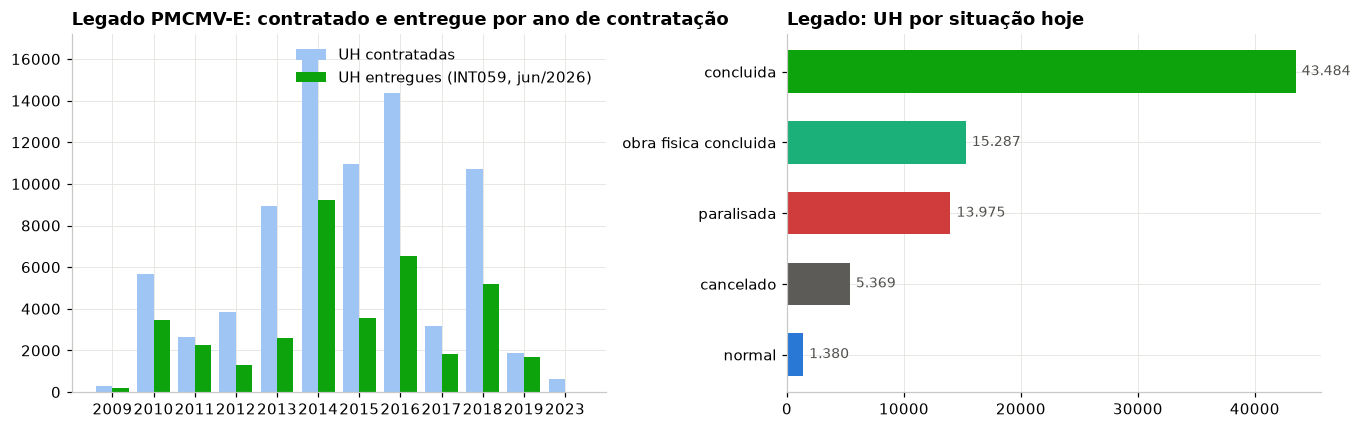

Legado (contratos de 2009 a 2019): 553 APFs, 79.495 UH contratadas, 37.853 entregues (48%); paralisadas: 76 com 13.975 UH
Tempo da contratação à entrega (mediana, 372 APFs com data): 38 meses; à conclusão da obra (245 APFs): 31 meses


In [24]:
# O legado PMCMV-E: contratado x entregue por ano de contratação, e quanto tempo levou
leg = cache("fds_legado_ultimo", """
select distinct on (apf) apf, nome_empreendimento, uf, municipio, quantidade_uh, quantidade_uh_entregues, status_operacional, situacao_canonica,
       dt_contratacao, dt_inicio_obra, dt_conclusao_obra, dt_entrega_uh, dt_paralisacao, percentual_execucao_fisica, valor_contratado, valor_desembolsado, motivo_paralisacao, dt_referencia
from prata.prata_hist_fds_empreendimento where fonte_serie = 'sftp' and apf not in (select apf from prata.prata_fds_empreendimento)
order by apf, dt_referencia desc""")
for c in ["dt_contratacao","dt_inicio_obra","dt_conclusao_obra","dt_entrega_uh","dt_paralisacao","dt_referencia"]: leg[c] = pd.to_datetime(leg[c])
leg = leg[leg.dt_contratacao < "2024-01-01"]
la = leg.groupby(leg.dt_contratacao.dt.year).agg(contratos=("apf","size"), uh=("quantidade_uh","sum"), entregues=("quantidade_uh_entregues","sum"))
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
x = np.arange(len(la)); w = 0.4
axes[0].bar(x - w/2, la.uh, w, color="#9ec5f4", label="UH contratadas"); axes[0].bar(x + w/2, la.entregues, w, color=STATUS["bom"], label="UH entregues (INT059, jun/2026)")
axes[0].set_xticks(x); axes[0].set_xticklabels(la.index); axes[0].legend(); axes[0].set_title("Legado PMCMV-E: contratado e entregue por ano de contratação")
st = leg.groupby("status_operacional").agg(contratos=("apf","size"), uh=("quantidade_uh","sum")).sort_values("uh")
axes[1].barh(st.index.str.replace("_", " ").str.lower(), st.uh, color=[{"CONCLUIDA": STATUS["bom"], "PARALISADA": STATUS["critico"], "OBRA_FISICA_CONCLUIDA": C["verde"], "CANCELADO": "#5c5b57", "NORMAL": C["azul"]}.get(i, C["cinza"]) for i in st.index], height=0.6)
axes[1].set_title("Legado: UH por situação hoje"); rotular_barras(axes[1], horizontal=True)
plt.tight_layout(); plt.show()
leg["m_contr_entrega"] = (leg.dt_entrega_uh - leg.dt_contratacao).dt.days/30.44
leg["m_contr_concl"] = (leg.dt_conclusao_obra - leg.dt_contratacao).dt.days/30.44
print(f"Legado (contratos de 2009 a 2019): {len(leg)} APFs, {num(leg.quantidade_uh.sum())} UH contratadas, {num(leg.quantidade_uh_entregues.sum())} entregues ({100*leg.quantidade_uh_entregues.sum()/leg.quantidade_uh.sum():.0f}%); paralisadas: {(leg.status_operacional == 'PARALISADA').sum()} com {num(leg[leg.status_operacional == 'PARALISADA'].quantidade_uh.sum())} UH")
print(f"Tempo da contratação à entrega (mediana, {leg.m_contr_entrega.notna().sum()} APFs com data): {leg.m_contr_entrega.median():.0f} meses; à conclusão da obra ({leg.m_contr_concl.notna().sum()} APFs): {leg.m_contr_concl.median():.0f} meses")

**Leitura.** A carteira nova entregou 64 UH, todas em quatro contratos de lotes pulverizados (a família recebe o lote e o contrato antes da casa ficar pronta); os três contratos "concluídos" são projetos concluídos, não obras. Nenhum campo de entrega do MONIT está preenchido. A promessa de conclusão já venceu para 115 contratos sem 100% (109 de projeto e 6 de obra, 8,4 mil UH), com o INT059 chamando a maioria de "normal". O legado diz o que esperar: dos 79,5 mil UH contratados entre 2009 e 2019, 48% foram entregues, 14 mil UH estão em obras paralisadas e a mediana da contratação à entrega foi de 38 meses, mais de três anos. É esse histórico que o notebook 03 usa para medir a vida de um contrato do Entidades.

## 8. Famílias, trabalho social e pós-ocupação

O mapa termina nos contratos individuais, na entrega das chaves e no trabalho social, que vai da mobilização das famílias ao pós-ocupação. O banco não tem beneficiários do FDS. Tem o trabalho social em dois lugares: a extração do MONIT (`prata.prata_fds_trabalho_social`, 141 APFs, com código de situação sem dicionário) e uma planilha da CAIXA de julho de 2026, ainda na bronze, que cobre 1.009 contratos (legado e novo) com a situação do TS e o motivo quando está atrasado ou paralisado.

MONIT trabalho social: 141 APFs; situação (código) e execução média:


,apfs,exec_media,com_pts_aprovado
co_situacao_trabalho_social,,,
1,59,45.0,59
2,15,100.0,15
5,62,0.0,62
6,5,30.1,5


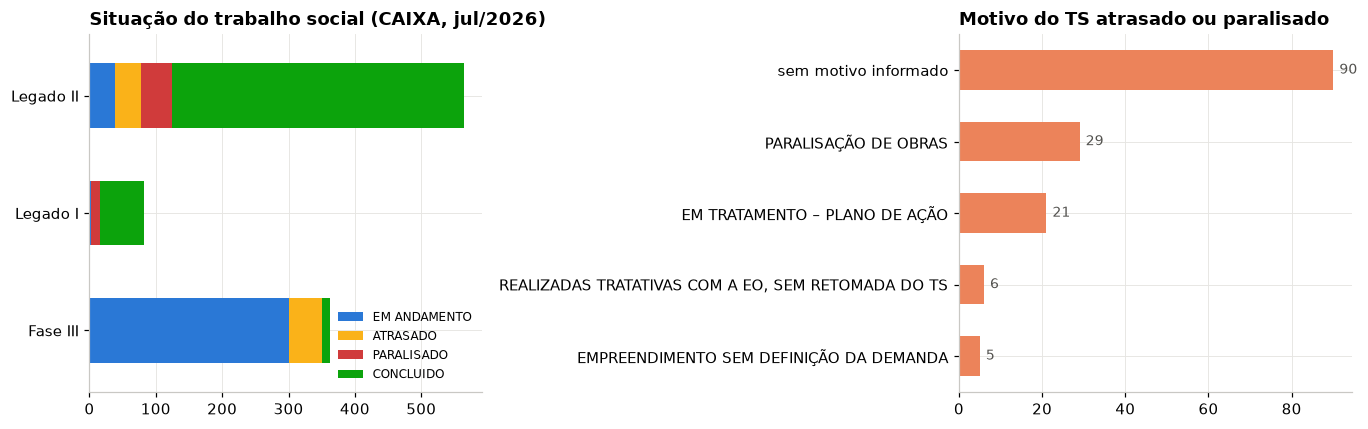

Carteira nova na planilha: 362 contratos; TS em andamento 299, atrasado 51, concluído 12; execução média do TS 30%


In [25]:
ts = cache("fds_trabalho_social", "select * from prata.prata_fds_trabalho_social")
print(f"MONIT trabalho social: {len(ts)} APFs; situação (código) e execução média:")
display(ts.groupby("co_situacao_trabalho_social").agg(apfs=("apf","size"), exec_media=("pct_execucao_ts","mean"), com_pts_aprovado=("dt_aprovacao_pts","count")).round(1))
tsb = cache("fds_ts_caixa_202607", """select contrato, municipio, uf, nome_empreendimento, uh, fase_mcmv, situacao_ts, motivo_situacao_ts_atrasado_paralisado, execucao_ts, obra,
       vr_global_ts, vr_desembolsado, natureza_execucao, instrumento_de_planejamento, data_da_contratacao from bronze.bronze_shpt_mcmv_fds_ts_caixa_202607""")
tsb["apf"] = tsb.contrato.str.replace(r"[^0-9]", "", regex=True).str.zfill(8); tsb["novo"] = tsb.apf.isin(emp.apf)
tsb["exec"] = pd.to_numeric(tsb.execucao_ts.astype(str).str.replace("%", "").str.replace(",", "."), errors="coerce")
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
t = pd.crosstab(tsb.fase_mcmv, tsb.situacao_ts)[["EM ANDAMENTO","ATRASADO","PARALISADO","CONCLUIDO"]]
t.plot.barh(stacked=True, ax=axes[0], color=[C["azul"], STATUS["atencao"], STATUS["critico"], STATUS["bom"]], width=0.55); axes[0].set_title("Situação do trabalho social (CAIXA, jul/2026)"); axes[0].set_ylabel(""); axes[0].legend(fontsize=8)
mot = tsb[tsb.situacao_ts.isin(["ATRASADO","PARALISADO"])].motivo_situacao_ts_atrasado_paralisado.replace("", np.nan).fillna("sem motivo informado").value_counts().sort_values()
axes[1].barh(mot.index.str[:50], mot.values, color=STATUS["serio"], height=0.55); axes[1].set_title("Motivo do TS atrasado ou paralisado"); rotular_barras(axes[1], horizontal=True)
plt.tight_layout(); plt.show()
n = tsb[tsb.novo]
print(f"Carteira nova na planilha: {len(n)} contratos; TS em andamento {int((n.situacao_ts == 'EM ANDAMENTO').sum())}, atrasado {int((n.situacao_ts == 'ATRASADO').sum())}, concluído {int((n.situacao_ts == 'CONCLUIDO').sum())}; execução média do TS {n.exec.mean():.0f}%")

<div style="border:2px solid #d03b3b;background:#fff4f4;padding:10px 14px;border-radius:6px;margin:6px 0"><b style="color:#d03b3b">⚠ Fora do banco: o trabalho social da CAIXA está na bronze, e o código do MONIT não tem dicionário</b><ul style="margin:6px 0 0 0"><li>A planilha <code>bronze.bronze_shpt_mcmv_fds_ts_caixa_202607</code> é cópia fiel do arquivo da CAIXA (texto puro, uma competência). Os números desta seção vêm dela, mas sem tipagem: a execução em texto foi convertida aqui.</li><li>O código <code>co_situacao_trabalho_social</code> (1, 2, 5, 6) da <code>prata_fds_trabalho_social</code> não tem dicionário no banco; a seed <code>ts_dominio_situacao</code> é por texto da CAIXA.</li><li><b>Como levar ao banco:</b> modelo <code>prata_fds_trabalho_social_caixa</code> (tipagem da planilha, com a competência) e a seed <code>fds_ts_situacao_codigo.csv</code> com o dicionário do MONIT_EXEC_TS, pedido ao GEFUS; a planilha é mensal e devia entrar pelo SFTP como as demais.</li></ul></div>

**Leitura.** O trabalho social do Entidades é executado pela própria entidade e acompanha a obra: na carteira nova está "em andamento" na maior parte dos contratos, atrasado em 51 e sem nenhum paralisado. No legado, 61 paralisados e 90 atrasados; o motivo, quando informado (61 dos 151 casos), é na maioria a paralisação da obra, seguido de "em tratamento com plano de ação" e de empreendimento sem definição da demanda. É a primeira fonte do banco com um motivo escrito pela CAIXA, e vale como modelo do que pedir para a obra. O que não existe: famílias (quem são, renda, mulher responsável), comissões (CRE e CAO), prestações pagas ao fundo e pós-ocupação; o secretário chamou esse último de módulo novo, a inaugurar com o DPSM.

## 9. Síntese: o fluxo da política e o que os dados respondem

| Etapa do mapa | Indicador | O que os dados dizem (jul/2026) | Fonte | Lacuna |
|---|---|---|---|---|
| Orçamento (00CY) | dotação, pago por exercício | 2024: R$ 1,2 bi pagos; 2025: LOA R$ 903 mi, pago R$ 172 mi; 2026: R$ 467 mi | prata SIAFI (2025), SIOP (demais) | saldo do FDS na CAIXA; série por exercício no banco |
| Planejamento e seleção | ciclos, portarias, propostas selecionadas | ciclo 2023/24: 364 contratos; ciclo 2025/26: 393 propostas, 35,8 mil UH, 0 contratos | cadastro PJ, seed 698/2026 | funil de propostas (apresentadas, enquadradas, não selecionadas) e a 355/2024 |
| Habilitação da EO | nível, UH por entidade, risco | 175 entidades; 23 de nível 1 com metade das UH; 2 em alto risco | cadastro PJ, panorama por EO | dicionário do nível; habilitação (SISAD) |
| Contratação | contratos por fase, UF, tipologia, regime, investimento | 182 projetos + 182 obras, R$ 3,46 bi, FDS R$ 2,63 bi; 31 em terreno da União | cadastro PJ, INT059, ficha | famílias e comissões; vínculo projeto → obra; dicionário do regime |
| Execução | GEFUS, MONIT, previsto x realizado, curva S por mês de contrato | 60 em cláusula suspensiva, 4 paralisados; obra típica com 10% no 12º mês | INT059, obra mensal, eixo histórico | GEHIS do FDS; série física contínua; motivo da paralisação |
| Desembolso | liberado por mês, patamares, composição | R$ 376 mi (14% do FDS contratado); ritmo de R$ 37 mi/mês; terreno e projeto 27% | livro-razão MONIT | régua de ritmo própria do FDS (antecipação) |
| Entrega | alienação, promessas vencidas, legado | 64 UH alienadas; 115 promessas vencidas; legado 48% entregue, mediana de 38 meses | obra mensal, cadastro PJ, INT059 histórico | campos de entrega do MONIT vazios |
| Famílias e TS | situação e motivo do TS | 51 TS atrasados na carteira nova; motivo mais comum no legado: obra paralisada | planilha CAIXA (bronze), MONIT TS | beneficiários, CRE/CAO, retornos ao fundo, pós-ocupação |

**Próximo notebook (03).** A vida de um contrato do Entidades sobre a escala do tempo: contrato de projeto, cláusula suspensiva, obra, alienação, com o legado como referência de quanto dura cada fase e onde o atraso acontece, e o caso da União por Moradia Popular da Paraíba, que tem um projeto concluído e duas obras paralisadas.